# Marketing Mix Model: where should the next £ go? 

**Question:** where should the brand spend more or less to win *new customers* efficiently, if one extra new customer may cost at most **£40**?
**Baseline:** September 2026 average daily spend, run for the next 30 days under normal trading (no promotions, no Black Friday / Cyber Monday).

**Changes vs v1 (review feedback)**
- Units are now explicit everywhere: £ per day vs £ over 30 days vs new customers over 30 days.
- Section 10a: cost per extra customer with 90% ranges, and response curves with the £40 ceiling.
- Section 4b: out-of-sample comparison against a regression with **no media** (seasonality, weekday, promotions only).
- Section 10b: model refit under reasonable assumption changes (`l_max`, yearly seasonality, Hill saturation) and check whether conclusions hold.
- Section 10c: reallocation across all four channels with the total budget unchanged (replaces the Pinterest→Bing rule).
- Section 11 recommendation updated to match.

In [1]:
import warnings, os, sys
warnings.filterwarnings("ignore")

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass
from scipy.optimize import minimize          # used in section 10c

import arviz as az
import pymc as pm
import pymc_marketing
from pymc_marketing.mmm import MMM, GeometricAdstock, LogisticSaturation, HillSaturation   # Hill used in 10b

print("python", sys.version.split()[0], "| pymc", pm.__version__, "| pymc-marketing", pymc_marketing.__version__)

# ----------------------------- settings -----------------------------
DATA_FILE = "MMM_Candidate_Brief.xlsx"       # the Excel file from the company
OUT_DIR = "outputs"                          # charts and tables are saved here
SEED = 42                                    # makes random numbers repeatable
CPA_TARGET = 40.0                            # max acceptable cost of one EXTRA new customer (£)
HORIZON = 30                                 # days we look ahead
HOLDOUT_DAYS = 56                            # last 8 weeks are hidden for the out-of-sample test
L_MAX = 8                                    # how many days an ad can keep working (adstock length)
HIST_DAYS = 30                               # real days before the horizon, so earlier ads still "echo"
N_KEEP = 1000                                # posterior draws used for the scenarios
CHAINS, DRAWS, TUNE = 4, 1000, 1000          # sampler size

CHANNELS = ["bing", "google", "meta", "pinterest"]
CONTROLS = ["promo_discount", "black_friday", "cyber_monday", "bfcm_window", "christmas",
            "dow_1", "dow_2", "dow_3", "dow_4", "dow_5", "dow_6"]

os.makedirs(OUT_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

g++ not available, if using conda: `conda install gxx`


python 3.13.9 | pymc 6.3.2 | pymc-marketing 1.3.0


## 1. Data and quality checks

In [2]:
raw = pd.read_excel(DATA_FILE, sheet_name="Daily Data")
assert raw.shape[1] == 15, f"Expected 15 columns, found {raw.shape[1]}"

raw.columns = [
    "date", "sales_inc_tax", "sales_ex_tax", "purchasing_customers", "orders", "new_customers",
    "bing", "google", "meta", "pinterest", "total_spend",
    "promo_discount", "black_friday", "cyber_monday", "bfcm_window",
]

# dates may arrive as real dates or as Excel serial numbers - handle both
if pd.api.types.is_numeric_dtype(raw["date"]):
    raw["date"] = pd.to_datetime(raw["date"], unit="D", origin="1899-12-30")
else:
    raw["date"] = pd.to_datetime(raw["date"])

df = raw.sort_values("date").reset_index(drop=True)
display(df.head())
print(df.shape, df["date"].min().date(), "->", df["date"].max().date())

,date,sales_inc_tax,sales_ex_tax,purchasing_customers,orders,new_customers,bing,google,meta,pinterest,total_spend,promo_discount,black_friday,cyber_monday,bfcm_window
0,2024-10-01,65244.10,54370.08,706,721,458,334.72,2657.94,2393.94,512.70,5899.30,0.0,0,0,0
1,2024-10-02,69274.63,57728.86,710,724,468,310.00,3087.64,2462.26,468.30,6328.20,0.0,0,0,0
2,2024-10-03,68498.62,57082.18,721,734,476,321.55,3215.14,2965.07,469.93,6971.69,0.0,0,0,0
3,2024-10-04,73992.31,61660.26,765,788,504,391.43,3018.59,3110.63,512.49,7033.14,0.0,0,0,0
4,2024-10-05,71122.07,59268.39,684,708,425,379.63,2492.08,2738.47,550.13,6160.31,0.0,0,0,0


(730, 15) 2024-10-01 -> 2026-09-30


In [3]:
checks = []
def add_check(name, ok, detail=""):
    checks.append({"check": name, "result": "PASS" if ok else "CHECK", "detail": detail})

all_days = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
missing_days = all_days.difference(df["date"])
add_check("No missing dates", len(missing_days) == 0,
          f"{len(df)} rows vs {len(all_days)} calendar days ({len(missing_days)} missing)")
add_check("No duplicate dates", not df["date"].duplicated().any(),
          f"{int(df['date'].duplicated().sum())} duplicates")
add_check("No missing values", df.isna().sum().sum() == 0, f"{int(df.isna().sum().sum())} empty cells")

numeric = df.drop(columns="date")
add_check("No negative numbers", (numeric < 0).sum().sum() == 0, f"{int((numeric < 0).sum().sum())} negatives")

gap = (df[CHANNELS].sum(axis=1) - df["total_spend"]).abs().max()
add_check("Channel spends add up to total spend", gap <= 0.05, f"largest gap £{gap:.2f}")

ratio = df["sales_inc_tax"] / df["sales_ex_tax"]
add_check("Sales incl. tax = 1.20 x excl. tax (20% VAT)", ratio.between(1.19, 1.21).all(),
          f"ratio between {ratio.min():.3f} and {ratio.max():.3f}")

order_ok = (df["new_customers"] <= df["purchasing_customers"]) & (df["purchasing_customers"] <= df["orders"])
add_check("new customers <= purchasing customers <= orders", order_ok.all(), f"{int((~order_ok).sum())} violations")

flags_ok = all(df[c].isin([0, 1]).all() for c in ["black_friday", "cyber_monday", "bfcm_window"])
add_check("Event flags contain only 0/1", flags_ok)
add_check("Promo discount is a fraction between 0 and 1 (0.25 = 25%)", df["promo_discount"].between(0, 1).all(),
          f"max {df['promo_discount'].max():.2f}")
add_check("BF and CM days lie inside the BF/CM window", ((df["black_friday"] + df["cyber_monday"]) <= df["bfcm_window"]).all())

display(pd.DataFrame(checks))

,check,result,detail
0,No missing dates,PASS,730 rows vs 730 calendar days (0 missing)
1,No duplicate dates,PASS,0 duplicates
2,No missing values,PASS,0 empty cells
3,No negative numbers,PASS,0 negatives
4,Channel spends add up to total spend,PASS,largest gap £0.00
5,Sales incl. tax = 1.20 x excl. tax (20% VAT),PASS,ratio between 1.200 and 1.200
6,new customers <= purchasing customers <= orders,PASS,0 violations
7,Event flags contain only 0/1,PASS,
8,Promo discount is a fraction between 0 and 1 (...,PASS,max 0.25
9,BF and CM days lie inside the BF/CM window,PASS,


In [4]:
# Units: not just stated, but checked against what a daily £ amount or a count should look like
unit_checks = []

for ch in CHANNELS + ["total_spend"]:
    lo, hi = df[ch].min(), df[ch].max()
    unit_checks.append({"column": ch, "min": round(lo, 2), "max": round(hi, 2),
                        "plausible?": "YES (£ per day)" if (lo >= 0 and hi < 100_000) else "CHECK"})

rev_per_spend = df["sales_ex_tax"].mean() / df["total_spend"].mean()
unit_checks.append({"column": "sales_ex_tax vs total_spend", "min": "-", "max": "-",
                    "plausible?": f"revenue / ad spend = {rev_per_spend:.1f}x ({'plausible' if 2 < rev_per_spend < 200 else 'CHECK'})"})

for col in ["purchasing_customers", "orders", "new_customers"]:
    frac = (df[col] % 1).max()
    unit_checks.append({"column": col, "min": int(df[col].min()), "max": int(df[col].max()),
                        "plausible?": "YES (whole numbers)" if frac < 0.01 else "CHECK (has decimals)"})

promo_max = df["promo_discount"].max()
unit_checks.append({"column": "promo_discount", "min": df["promo_discount"].min(), "max": promo_max,
                    "plausible?": "YES (fraction, 0.25 = 25%)" if promo_max <= 1 else "CHECK (looks like % not fraction)"})
display(pd.DataFrame(unit_checks))

aov = (df["sales_ex_tax"] / df["orders"]).mean()
print(f"Total spend over 2 years: £{df['total_spend'].sum():,.0f}")
print(f"Average order value (sales ex tax / orders): £{aov:.2f} - {'plausible for e-commerce' if 20 < aov < 500 else 'CHECK'}")
print(f"New customers per day: min {df.new_customers.min():.0f}, median {df.new_customers.median():.0f}, max {df.new_customers.max():.0f}")

,column,min,max,plausible?
0,bing,98.0,1069.95,YES (£ per day)
1,google,848.27,13487.88,YES (£ per day)
2,meta,518.24,19251.13,YES (£ per day)
3,pinterest,56.59,3029.0,YES (£ per day)
4,total_spend,1993.5,36653.03,YES (£ per day)
5,sales_ex_tax vs total_spend,-,-,revenue / ad spend = 9.0x (plausible)
6,purchasing_customers,231,3020,YES (whole numbers)
7,orders,236,3088,YES (whole numbers)
8,new_customers,127,2290,YES (whole numbers)
9,promo_discount,0.0,0.25,"YES (fraction, 0.25 = 25%)"


Total spend over 2 years: £4,383,041
Average order value (sales ex tax / orders): £78.64 - plausible for e-commerce
New customers per day: min 127, median 385, max 2290


In [5]:
# Unusual days: how far is each day from its own surroundings?
# Rolling median + MAD (median absolute deviation). The threshold comes from the data's own spread,
# so it adapts to quiet and busy seasons instead of using a fixed cut-off.
WINDOW = 21          # 3 weeks: wide enough not to swallow a short peak
THRESHOLD = 3.5      # in MAD units (common range 2.5-3.5)
BUDGET_COL = "total_spend"

rolling_med = df["new_customers"].rolling(WINDOW, center=True, min_periods=7).median()
abs_dev = (df["new_customers"] - rolling_med).abs()
rolling_mad = abs_dev.rolling(WINDOW, center=True, min_periods=7).median()
# 0.6745 makes MAD comparable to a standard deviation; 1e-9 avoids dividing by zero
modified_z = 0.6745 * (df["new_customers"] - rolling_med) / (rolling_mad + 1e-9)

odd = df.loc[modified_z.abs() > THRESHOLD,
             ["date", "new_customers", BUDGET_COL, "promo_discount", "bfcm_window", "black_friday", "cyber_monday"]].copy()
odd["rolling_median"] = rolling_med[odd.index].round(0)
odd["modified_z_score"] = modified_z[odd.index].round(2)
odd["direction"] = (odd["new_customers"] > odd["rolling_median"]).map({True: "up", False: "down"})

# did ad spend move too? compare it with its own normal level
rolling_spend_med = df[BUDGET_COL].rolling(WINDOW, center=True, min_periods=7).median()
odd["rolling_median_spend"] = rolling_spend_med[odd.index].round(2)
odd["spend_direction"] = (odd[BUDGET_COL] > odd["rolling_median_spend"]).map({True: "up", False: "down/same"})

display(odd.sort_values("modified_z_score").reset_index(drop=True))
print(f"\nThreshold |z| > {THRESHOLD} (window {WINDOW} days). Found {len(odd)} unusual days out of {len(df)}.")

,date,new_customers,total_spend,promo_discount,bfcm_window,black_friday,cyber_monday,rolling_median,modified_z_score,direction,rolling_median_spend,spend_direction
0,2025-12-24,177,3942.05,0.00,0,0,0,645.0,-4.57,down,8023.81,down/same
1,2024-12-24,130,2173.33,0.00,0,0,0,449.0,-4.30,down,3654.18,down/same
2,2024-12-25,127,1993.50,0.00,0,0,0,443.0,-4.18,down,3543.30,down/same
3,2025-08-30,258,3783.37,0.00,0,0,0,326.0,-4.17,down,3771.15,up
4,2025-12-25,190,3801.80,0.00,0,0,0,608.0,-4.09,down,7897.13,down/same
5,2025-06-29,403,4982.87,0.00,0,0,0,333.0,3.63,up,4625.44,up
6,2025-10-26,595,6851.86,0.00,0,0,0,498.0,3.63,up,6982.70,down/same
7,2026-03-15,452,6284.26,0.00,0,0,0,386.0,3.71,up,5982.14,up
8,2025-09-07,390,3492.68,0.00,0,0,0,329.0,3.74,up,3806.91,down/same
9,2026-06-21,664,8402.59,0.10,0,0,0,411.0,4.16,up,7224.18,up



Threshold |z| > 3.5 (window 21 days). Found 23 unusual days out of 730.


All 10 checks passed: 730 days in a row, no gaps, duplicates, empty or negative cells; channel spends add up to the total; sales incl. tax are exactly 1.20x sales excl. tax (20% VAT); customers never exceed orders. Units look right as well: spend in £ per day (£4.4M over two years), average order £78.64, discount stored as a fraction. These are sanity checks, not proof, but nothing suspicious is noticeable.

Unusual days (23 flagged). Almost all have a clear story:
- Black Friday / Cyber Monday weeks: customers, discounts (10-25%) and ad spend all jump together.
- Christmas Eve and Day, both years: new customers about 70% below normal, ad spend 40-50% below normal.
- 10% discount weeks in June: customers 31-62% above normal, while spend is at most 18% above normal.
- Four ordinary Sundays (17-21% above the rolling median, spend within +/-8% of normal): Sunday is simply the strongest weekday. The model has day-of-week controls for this.
- 30 Aug 2025 (a Saturday): customers 21% below normal at normal spend. The data do not say why, so I treat it as noise (one day out of 730).

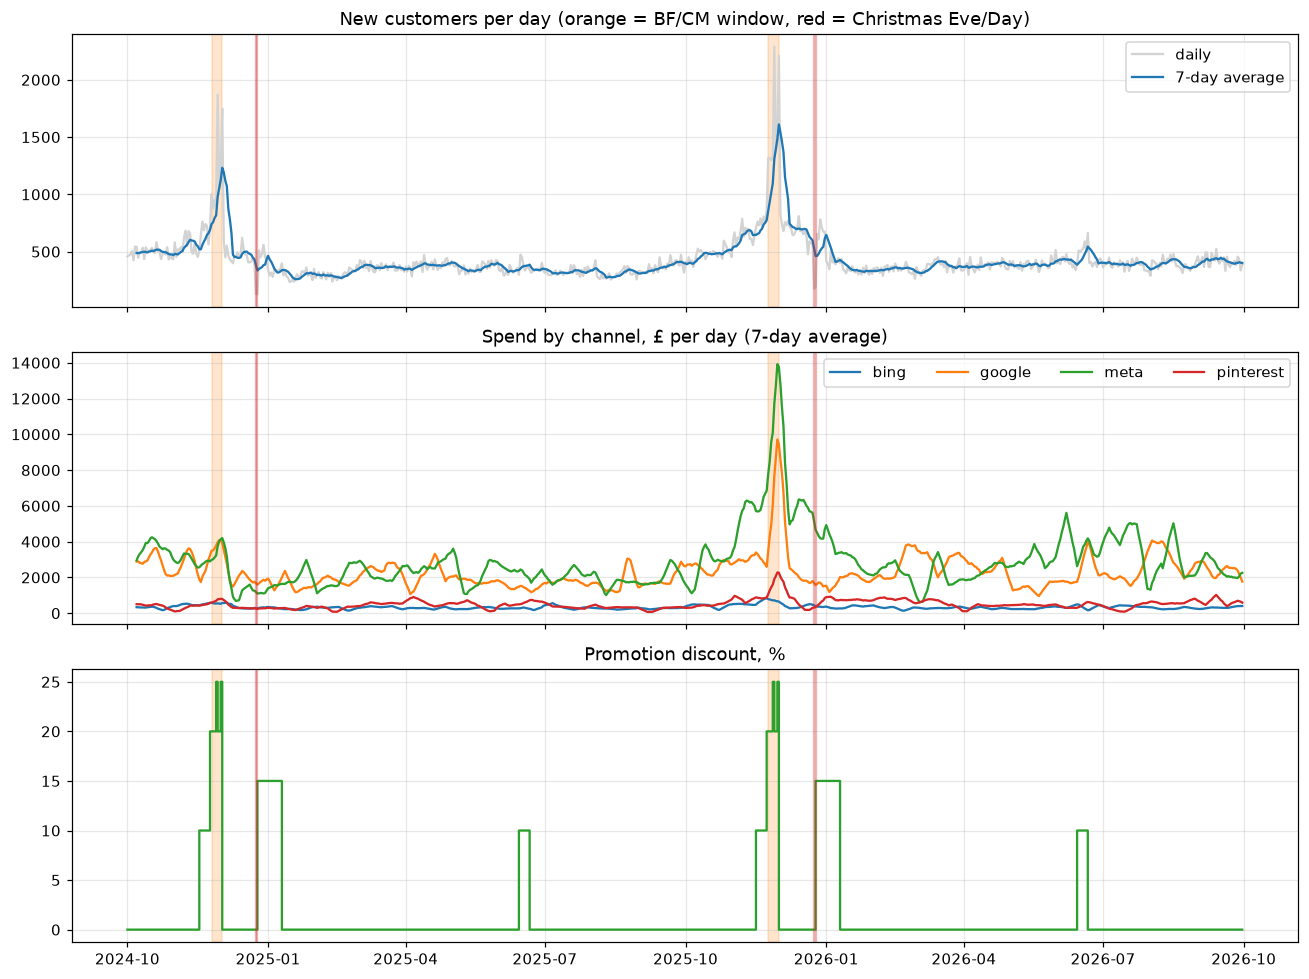

In [6]:
# features the model needs
df["christmas"] = ((df["date"].dt.month == 12) & (df["date"].dt.day.isin([24, 25]))).astype(int)
dow = df["date"].dt.dayofweek                      # Monday = 0 ... Sunday = 6
for d in range(1, 7):
    df[f"dow_{d}"] = (dow == d).astype(int)        # Monday is the reference day

def shade_events(ax):
    win = df["bfcm_window"].to_numpy()
    starts = df.index[(win == 1) & (np.r_[0, win[:-1]] == 0)]
    ends = df.index[(win == 1) & (np.r_[win[1:], 0] == 0)]
    for s, e in zip(starts, ends):
        ax.axvspan(df["date"][s], df["date"][e], color="tab:orange", alpha=0.2)
    for d in df.loc[df["christmas"] == 1, "date"]:
        ax.axvline(d, color="tab:red", alpha=0.35)

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(df["date"], df["new_customers"], color="lightgrey", label="daily")
axes[0].plot(df["date"], df["new_customers"].rolling(7).mean(), color="tab:blue", label="7-day average")
axes[0].set_title("New customers per day (orange = BF/CM window, red = Christmas Eve/Day)")
axes[0].legend(); shade_events(axes[0])

for ch in CHANNELS:
    axes[1].plot(df["date"], df[ch].rolling(7).mean(), label=ch)
axes[1].set_title("Spend by channel, £ per day (7-day average)")
axes[1].legend(ncol=4); shade_events(axes[1])

axes[2].step(df["date"], df["promo_discount"] * 100, color="tab:green")
axes[2].set_title("Promotion discount, %"); shade_events(axes[2])
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/01_overview.png"); plt.show()

In [7]:
# Black Friday 2024 vs 2025: same discount schedule, very different spend
rows = []
for y in (2024, 2025):
    sale = df[(df["date"] >= f"{y}-11-01") & (df["date"] <= f"{y}-12-05") & (df["promo_discount"] > 0)]
    start = sale["date"].min()
    pre = df[(df["date"] >= start - pd.Timedelta(days=45)) & (df["date"] <= start - pd.Timedelta(days=15))]
    rows.append({"year": y, "sale from": start.date(), "to": sale["date"].max().date(), "days": len(sale),
                 "avg discount": sale["promo_discount"].mean(),
                 "sale spend £": sale["total_spend"].sum(), "sale new customers": sale["new_customers"].sum(),
                 "pre-sale customers/day": pre["new_customers"].mean(), "pre-sale spend £/day": pre["total_spend"].mean()})
bf = pd.DataFrame(rows).set_index("year")
display(bf.round(2))

extra_spend_bf = bf.loc[2025, "sale spend £"] - bf.loc[2024, "sale spend £"]
extra_cust_bf = bf.loc[2025, "sale new customers"] - bf.loc[2024, "sale new customers"]
print(f"2025 vs 2024: spend x{bf.loc[2025, 'sale spend £'] / bf.loc[2024, 'sale spend £']:.2f}, "
      f"new customers {extra_cust_bf / bf.loc[2024, 'sale new customers']:+.0%}")
print(f"The extra £{extra_spend_bf:,.0f} of spend came with {extra_cust_bf:,.0f} extra new customers -> about £{extra_spend_bf / extra_cust_bf:,.0f} each")
print("Crude: two different years, other things changed too. A sanity check, not an estimate.")

,sale from,to,days,avg discount,sale spend £,sale new customers,pre-sale customers/day,pre-sale spend £/day
year,,,,,,,,
2024,2024-11-18,2024-12-02,15,0.16,126328.21,14451,494.65,6908.09
2025,2025-11-17,2025-12-01,15,0.16,284806.52,18010,489.35,6677.57


2025 vs 2024: spend x2.25, new customers +25%
The extra £158,478 of spend came with 3,559 extra new customers -> about £45 each
Crude: two different years, other things changed too. A sanity check, not an estimate.


- New customers peak every year in Black Friday / Cyber Monday week, drop sharply on Christmas Eve and Day, then bounce back with the 15% post-Christmas sale.
- Meta is the biggest budget (48% of two-year spend), then Google (38%), Pinterest (8%) and Bing (about 5-6%). Meta and Google both ramp up hard in sale periods, most of all in 2025.
- Outside sales, new customers sit at a fairly steady 320-400 a day (higher in autumn).
- Same discounts, very different spend. The 2024 and 2025 sales had the same discount schedule, yet 2025 spend was 2.25x higher while new customers rose only 25%, and the normal level before the sale was the same in both years. More money bought less than proportional growth. This is a rough comparison of two years, not a model result.

## 2. Baseline plan (September 2026 average daily spend)

In [8]:
sept = df[(df["date"] >= "2026-09-01") & (df["date"] <= "2026-09-30")]
assert len(sept) == 30

if sept["promo_discount"].max() > 0 or sept["bfcm_window"].max() > 0:
    print("WARNING: September 2026 contains promotions or BF/CM days - decide what 'normal trading' means and note it.")
else:
    print("OK: September 2026 had no promotions and no BF/CM days, so it is a clean 'normal trading' reference.")

base_daily = sept[CHANNELS].mean()                       # £ per day, per channel
base_new_30d = sept["new_customers"].mean() * HORIZON    # reference level of new customers over 30 days
hist = df[CHANNELS].tail(HIST_DAYS).to_numpy()           # real spend of the last days (carry-over into the horizon)

summary = pd.DataFrame({
    "avg daily spend £": base_daily.round(2),
    "share of total": (base_daily / base_daily.sum()).round(3),
    "30-day spend £": (base_daily * HORIZON).round(0),
})
display(summary)
print(f"Total: £{base_daily.sum():,.0f} per day, £{base_daily.sum() * HORIZON:,.0f} over {HORIZON} days")
print(f"September 2026 new customers per day: {sept['new_customers'].mean():.1f}  -> reference for {HORIZON} days: {base_new_30d:,.0f}")
print(f"Average cost per new customer in September (ALL spend / ALL new customers): "
      f"£{sept['total_spend'].sum() / sept['new_customers'].sum():.2f}")
print("This is an AVERAGE. The £40 limit applies to the cost of EXTRA customers (the margin), which is higher.")

OK: September 2026 had no promotions and no BF/CM days, so it is a clean 'normal trading' reference.


,avg daily spend £,share of total,30-day spend £
bing,331.44,0.058,9943.0
google,2264.95,0.395,67949.0
meta,2509.40,0.437,75282.0
pinterest,634.51,0.111,19035.0


Total: £5,740 per day, £172,209 over 30 days
September 2026 new customers per day: 418.6  -> reference for 30 days: 12,558
Average cost per new customer in September (ALL spend / ALL new customers): £13.71
This is an AVERAGE. The £40 limit applies to the cost of EXTRA customers (the margin), which is higher.


Baseline is £5,740 a day (£172k over 30 days) for about 419 new customers a day, so 12,558 over 30 days. The average new customer costs £13.71, but that is an average. The £40 limit is about the next customer, and the next one always costs more.

## 3. The model
New customers per day = baseline level + yearly season + controls (discount, BF/CM flags, Christmas, weekday) + the four channels. Each channel's spend gets two twists: adstock (an ad keeps working for a few days, fading a bit each day) and saturation (each extra £ adds less than the last one). It is Bayesian, so every number comes with a range.

After fitting, I check the model's global parameters: adstock (ad memory), saturation (diminishing returns), sigma (noise), intercept (baseline) and gamma (controls such as Black Friday and discount). If the sampler did not settle on those, nothing built on top can be trusted.

In [9]:
MODEL_COLS = ["date"] + CHANNELS + CONTROLS

@dataclass
class Fit:
    mmm: object
    data: pd.DataFrame
    l_max: int
    tgt_scale: float
    ch_scale: np.ndarray

def fit_model(data, l_max=L_MAX, yearly_seasonality=2, draws=DRAWS, tune=TUNE, chains=CHAINS):
    data = data.reset_index(drop=True)
    X = data[MODEL_COLS]
    y = data["new_customers"].rename("y")          # the library expects the target to be called "y"
    mmm = MMM(
        date_column="date",
        channel_columns=CHANNELS,
        control_columns=CONTROLS,
        adstock=GeometricAdstock(l_max=l_max),
        saturation=LogisticSaturation(),
        yearly_seasonality=yearly_seasonality,     # smooth yearly wave (2 Fourier terms)
    )
    mmm.fit(X=X, y=y, chains=chains, draws=draws, tune=tune, target_accept=0.9, random_seed=SEED)
    # PyMC-Marketing divides spend and target by their maximum (max-abs scaling); we keep those numbers
    return Fit(mmm=mmm, data=data, l_max=l_max, tgt_scale=float(y.max()), ch_scale=X[CHANNELS].max().to_numpy())

def diagnostics(fit):
    idata = fit.mmm.idata
    keep = [v for v in idata.posterior.data_vars
            if any(k in v for k in ("adstock", "saturation", "sigma", "intercept", "gamma"))]
    summ = az.summary(idata, var_names=keep)
    div = int(idata.sample_stats["diverging"].sum())
    print(f"max r_hat  = {summ['r_hat'].max():.3f}   (want < 1.01)")
    print(f"min ESS    = {summ['ess_bulk'].min():.0f}    (want > 400)")
    print(f"divergences= {div}      (want 0 or very few)")
    return summ

def to_draws(pred, n_last, y_mean, tgt_scale):
    """Turn PyMC-Marketing's prediction object into a plain array: (draws, days)."""
    if hasattr(pred, "data_vars"):
        names = list(pred.data_vars)
        da = pred["y"] if "y" in names else pred[names[0]]
    else:
        da = pred
    dims = list(da.dims)
    time_dim = "date" if "date" in dims else [d for d in dims if d not in ("chain", "draw", "sample")][-1]
    other = [d for d in dims if d != time_dim]
    arr = np.asarray(da.transpose(*other, time_dim).values)
    arr = arr.reshape(-1, arr.shape[-1])[:, -n_last:]
    if arr.mean() < 0.05 * y_mean:          # values look scaled to 0-1: bring them back to customers
        print("NOTE: predictions looked scaled, multiplying by the target scale.")
        arr = arr * tgt_scale
    return arr

def forecast(fit, future_df, prepend=True):
    """Predict new customers for future_df. For days AFTER the training period, the last days of
    training data are put in front, so that the adstock 'echo' of earlier spend is not lost."""
    if prepend:
        ext = pd.concat([fit.data.tail(HIST_DAYS), future_df], ignore_index=True)[MODEL_COLS]
    else:
        ext = future_df[MODEL_COLS].reset_index(drop=True)
    pred = fit.mmm.sample_posterior_predictive(ext, extend_idata=False, combined=False)
    return to_draws(pred, len(future_df), fit.data["new_customers"].mean(), fit.tgt_scale)

## 4. Out-of-sample test: hide the last 8 weeks
The model is trained only on data before the test period, then asked to predict the hidden weeks. I compare it with two simple forecasts that ignore advertising completely.

last 8 weeks: train 674 days (to 2026-08-05), test 56 days


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [adstock_alpha, saturation_lam, saturation_beta, gamma_fourier, gamma_control, intercept_contribution, y_sigma]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 280 seconds.


Output()

max r_hat  = 1.005   (want < 1.01)
min ESS    = 1240    (want > 400)
divergences= 0      (want 0 or very few)


... (2 outputs left out)

NOTE: predictions looked scaled, multiplying by the target scale.


,MAE,MAPE %,RMSE
MMM (mean forecast),25.7,6.2,32.9
Naive: flat 28-day average,40.4,9.5,51.9
"Naive: same weekday, last 4 weeks",38.6,9.1,47.9


Share of actual days inside the 90% prediction range: 98% (ideal is about 90%)
Average error by week (%):


,MMM error %,Naive (weekday) error %
week,,
1,5.0,8.0
2,4.1,9.8
3,4.0,6.8
4,7.1,8.4
5,7.4,9.9
6,9.5,13.7
7,7.0,8.5
8,5.9,8.3


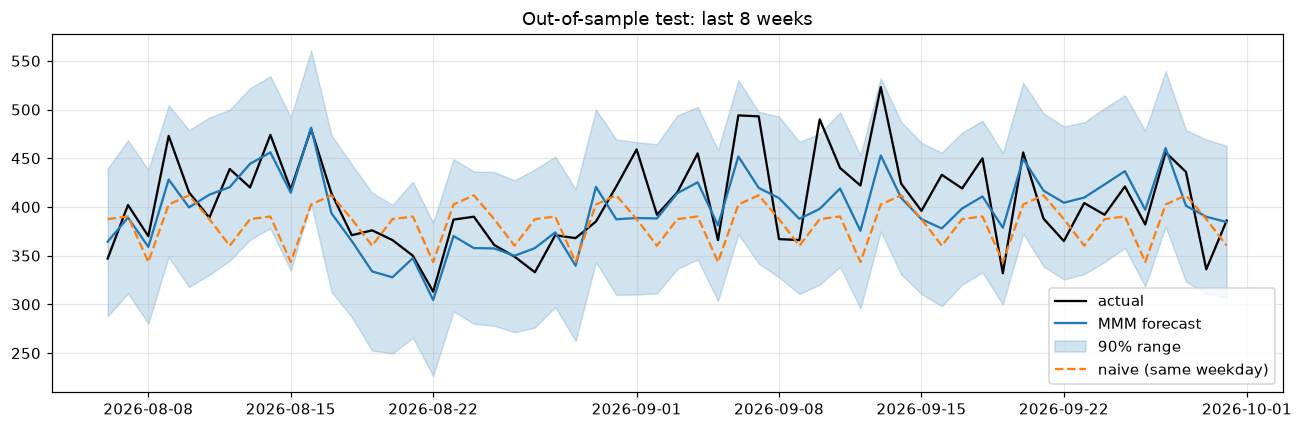

In [10]:
def metrics(actual, pred):
    err = pred - actual
    return {"MAE": np.mean(np.abs(err)),
            "MAPE %": np.mean(np.abs(err) / actual) * 100,
            "RMSE": np.sqrt(np.mean(err ** 2))}

def evaluate_holdout(data, test_start, test_end, label):
    train = data[data["date"] < test_start].reset_index(drop=True)
    test = data[(data["date"] >= test_start) & (data["date"] <= test_end)].reset_index(drop=True)
    print(f"{label}: train {len(train)} days (to {train['date'].max().date()}), test {len(test)} days")
    fit_tr = fit_model(train)
    diagnostics(fit_tr)

    draws = forecast(fit_tr, test)                         # (draws, days)
    actual = test["new_customers"].to_numpy()
    mean = draws.mean(axis=0)
    lo, hi = np.percentile(draws, [5, 95], axis=0)

    last28 = train.tail(28)
    flat = np.full(len(test), last28["new_customers"].mean())
    by_dow = last28.groupby(last28["date"].dt.dayofweek)["new_customers"].mean()
    seasonal_naive = test["date"].dt.dayofweek.map(by_dow).to_numpy()

    table = pd.DataFrame({
        "MMM (mean forecast)": metrics(actual, mean),
        "Naive: flat 28-day average": metrics(actual, flat),
        "Naive: same weekday, last 4 weeks": metrics(actual, seasonal_naive),
    }).T.round(1)
    coverage = float(np.mean((actual >= lo) & (actual <= hi)))

    weekly = pd.DataFrame({
        "week": (test["date"] - test["date"].min()).dt.days // 7 + 1,
        "MMM error %": np.abs(mean - actual) / actual * 100,
        "Naive (weekday) error %": np.abs(seasonal_naive - actual) / actual * 100,
    }).groupby("week").mean().round(1)

    display(table)
    print(f"Share of actual days inside the 90% prediction range: {coverage:.0%} (ideal is about 90%)")
    print("Average error by week (%):"); display(weekly)

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(test["date"], actual, color="black", label="actual")
    ax.plot(test["date"], mean, color="tab:blue", label="MMM forecast")
    ax.fill_between(test["date"], lo, hi, color="tab:blue", alpha=0.2, label="90% range")
    ax.plot(test["date"], seasonal_naive, color="tab:orange", ls="--", label="naive (same weekday)")
    ax.set_title(f"Out-of-sample test: {label}"); ax.legend()
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/02_holdout_{label.replace(' ', '_')}.png"); plt.show()
    return {"fit": fit_tr, "table": table, "weekly": weekly, "coverage": coverage}

test_start = df["date"].max() - pd.Timedelta(days=HOLDOUT_DAYS - 1)
ho = evaluate_holdout(df, test_start, df["date"].max(), "last 8 weeks")

Max r_hat 1.005, min ESS 1,240, no divergences: the four chains agree and the sampler had no trouble. That says the fitting worked, not that the model is right. The tests below do that job.

What the hidden 8 weeks show
- The model beats both naive forecasts: MAE 25.7 vs 38.6-40.4 customers (MAPE 6.2% vs 9.1-9.5%), and it wins in every single week (4-9% error vs 7-14%).
- The model is given the real ad spend of those weeks and the naive forecasts are not, and the period is calm (no promotions). A useful test, not a hard one.
- No upward drift in the weekly error; the worst week is week 6 (9.4%).
- It follows the trend but misses some sharp highs and lows.
- 98% of days landed inside the 90% range, so the range is too wide rather than too tight. Probably, a single, constant noise level is estimated based on all 730 days, including periods of intense, high-volume sales.
- Good enough to compare spending plans for the next 30 days. Not proof that it works in sale periods.

## 4b. Does advertising add anything? Regression with NO media channels
A regression that only sees seasonality, weekday, and promotions shows what the calendar alone can explain.
If it predicts the hidden 8 weeks about as well as the MMM, the ad channels add nothing measurable on calm weeks.
Same train/test split as section 4. Ordinary least squares, no advertising columns.

,MAE,MAPE %,RMSE
MMM (with ads),25.7,6.2,32.9
"Regression, no media",57.1,13.7,69.8
Naive: same weekday,38.6,9.1,47.9
Naive: flat 28-day average,40.4,9.5,51.9


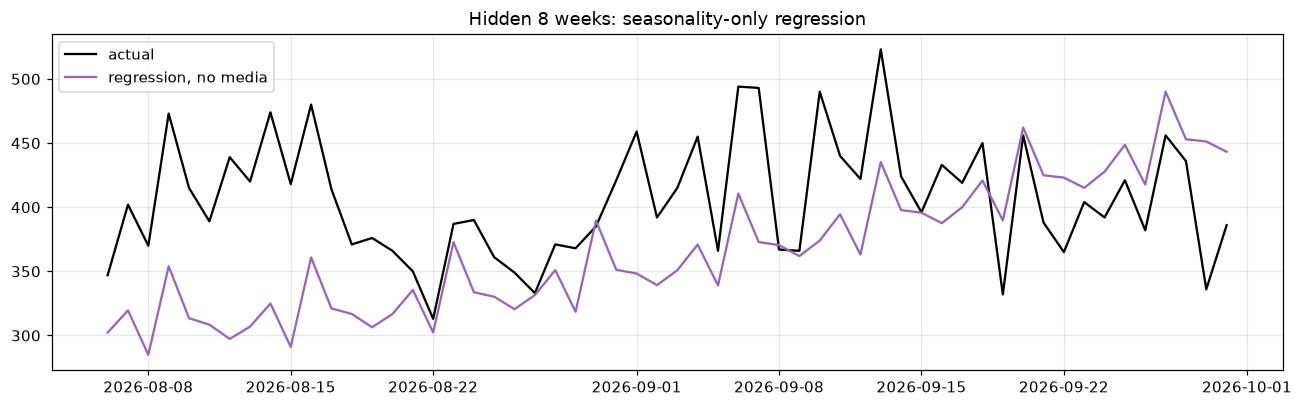

In [11]:
# Seasonal design without any media: intercept, 2 yearly Fourier pairs (same as the MMM), and the controls
def season_design(d, K=2):
    doy = d["date"].dt.dayofyear.to_numpy()
    cols = [np.ones(len(d))]                                    # 1) base level
    for k in range(1, K + 1):                                   # 2) yearly seasonal waves
        cols += [np.sin(2 * np.pi * k * doy / 365.25), np.cos(2 * np.pi * k * doy / 365.25)]
    return np.column_stack(cols + [d[c].to_numpy(float) for c in CONTROLS])   # 3) promo, BF/CM, Christmas, weekdays

train_nm = df[df["date"] < test_start].reset_index(drop=True)
test_nm = df[df["date"] >= test_start].reset_index(drop=True)
coef, *_ = np.linalg.lstsq(season_design(train_nm), train_nm["new_customers"].to_numpy(), rcond=None)
pred_nm = season_design(test_nm) @ coef
actual_nm = test_nm["new_customers"].to_numpy()

# repeat the naive baselines on the same split so the table is directly comparable
last28_nm = train_nm.tail(28)
by_dow_nm = last28_nm.groupby(last28_nm["date"].dt.dayofweek)["new_customers"].mean()
naive_wd = test_nm["date"].dt.dayofweek.map(by_dow_nm).to_numpy()
naive_flat = np.full(len(test_nm), last28_nm["new_customers"].mean())

cmp_tbl = pd.DataFrame({
    "MMM (with ads)": ho["table"].loc["MMM (mean forecast)"],
    "Regression, no media": metrics(actual_nm, pred_nm),
    "Naive: same weekday": metrics(actual_nm, naive_wd),
    "Naive: flat 28-day average": metrics(actual_nm, naive_flat),
}).T.round(1)
display(cmp_tbl)
cmp_tbl.to_csv(f"{OUT_DIR}/holdout_with_nomedia_baseline.csv")

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(test_nm["date"], actual_nm, color="black", label="actual")
ax.plot(test_nm["date"], pred_nm, color="tab:purple", label="regression, no media")
ax.set_title("Hidden 8 weeks: seasonality-only regression"); ax.legend(); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/02b_holdout_no_media.png"); plt.show()

The regression without media shows a significantly higher MAPE (13.7%) compared to both the marketing mix model (MMM - 6.2%) and naive methods (~9.1–9.5%), which proves that advertising brings important predictive value to the model.

## 5. Final model on all data

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [adstock_alpha, saturation_lam, saturation_beta, gamma_fourier, gamma_control, intercept_contribution, y_sigma]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 359 seconds.


Output()

max r_hat  = 1.002   (want < 1.01)
min ESS    = 1476    (want > 400)
divergences= 0      (want 0 or very few)


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
adstock_alpha[bing],0.257,0.179,0.022,0.58,3461,1922,1.00,0.0026,0.0025
adstock_alpha[google],0.259,0.124,0.06,0.47,3293,1844,1.00,0.0021,0.0018
adstock_alpha[meta],0.648,0.045,0.57,0.72,3512,2936,1.00,0.00077,0.00072
adstock_alpha[pinterest],0.209,0.194,0.012,0.61,3498,2273,1.00,0.0032,0.0038
saturation_lam[bing],1.65,1.17,0.33,3.8,2188,1778,1.00,0.021,0.028
saturation_lam[google],6.95,1.87,4.2,10,1476,1523,1.00,0.048,0.029
saturation_lam[meta],1.15,0.51,0.43,2,1982,1898,1.00,0.011,0.0073
saturation_lam[pinterest],2,1.35,0.4,4.4,2324,2055,1.00,0.024,0.023
saturation_beta[bing],0.073,0.1,0.018,0.2,2029,1608,1.00,0.0027,0.0095
saturation_beta[google],0.0817,0.0119,0.067,0.1,1853,1535,1.00,0.00031,0.00045


Sampling: [y]


Output()

NOTE: predictions looked scaled, multiplying by the target scale.
In-sample MAPE: 8.1%   (this is NOT a test - the model has seen these days)


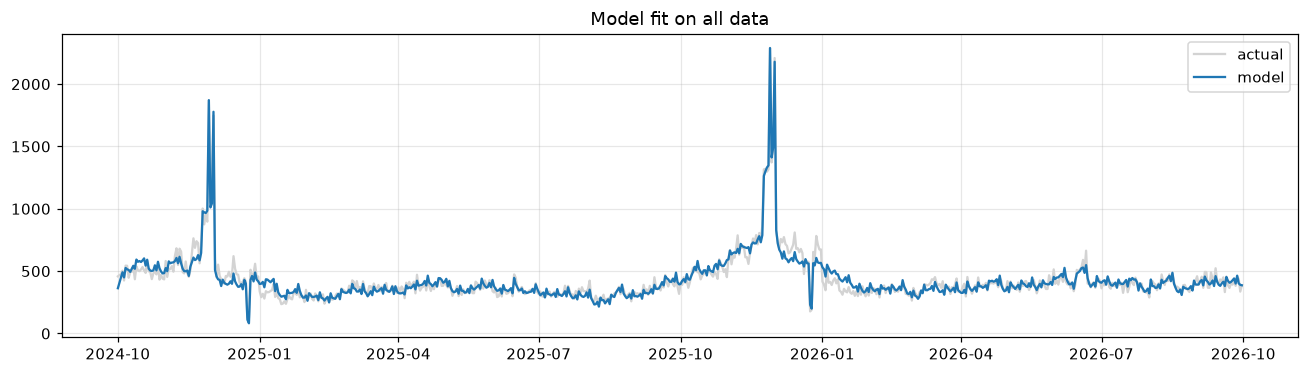

In [12]:
fit_full = fit_model(df)
diag = diagnostics(fit_full)
display(diag.loc[[i for i in diag.index if any(k in i for k in ("adstock", "saturation", "sigma"))]])

# in-sample fit
dr = forecast(fit_full, df, prepend=False)                   # predict the training period itself
m_in = dr.mean(axis=0)
y_all = df["new_customers"].to_numpy()
print("In-sample MAPE: {:.1f}%   (this is NOT a test - the model has seen these days)".format(
    np.mean(np.abs(m_in - y_all) / y_all) * 100))
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(df["date"], y_all, color="lightgrey", label="actual"); ax.plot(df["date"], m_in, color="tab:blue", label="model")
ax.set_title("Model fit on all data"); ax.legend(); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/03_insample_fit.png"); plt.show()

- Clean fit max r_hat = 1.002, min ESS = 1,476, no divergences.
- Meta's is the longest and best pinned down: alpha 0.65 (89% interval 0.57-0.72), with about 75% of its effect landing within three days. Bing, Google and Pinterest sit around 0.2-0.26 with wide intervals. Google's is clearly shorter than Meta's; for Bing and Pinterest the intervals overlap Meta's, so I can't rank them with confidence.
- Google's is the largest (6.95), so it saturates fastest. Meta's is small (1.15) with a wide interval (0.43-2): at today's spend its curve is nearly straight.
- Strength (beta) can't be compared between channels (each has its own scale and curve), so I compare marginal costs instead.
- Noise - y_sigma = 0.020 on the model's 0-1 scale, about 46 customers a day, roughly 12% of a typical day.
- The MAPE on the training set is 8% — the model has "seen" this data; the spikes in sales are largely explained by discounts and "Black Friday" labels. This is not a test set.

## 6. The channel maths, re-implemented (used for scenarios and checks)
For each channel and day: spend / max spend -> adstock -> saturation -> x beta x target scale = customers. I coded this in NumPy and checked that it reproduces PyMC-Marketing's own channel contributions before using it.

In [13]:
def pick(post, prefix):
    names = [v for v in post.data_vars if v.startswith(prefix)]
    assert names, f"No variable starting with '{prefix}' in the posterior. Found: {list(post.data_vars)}"
    return post[names[0]]

def get_params(fit, n_keep=N_KEEP, seed=SEED):
    post = fit.mmm.idata.posterior
    out = {}
    for key, prefix in [("alpha", "adstock_alpha"), ("lam", "saturation_lam"), ("beta", "saturation_beta")]:
        da = pick(post, prefix)
        order = [str(c) for c in da.coords["channel"].values]
        arr = np.asarray(da.transpose("chain", "draw", "channel").values)
        arr = arr.reshape(-1, arr.shape[-1])[:, [order.index(c) for c in CHANNELS]]
        out[key] = arr
    total = out["alpha"].shape[0]
    sel = np.sort(np.random.default_rng(seed).choice(total, size=min(n_keep, total), replace=False))
    for k in ("alpha", "lam", "beta"):
        out[k] = out[k][sel]
    out.update(sel=sel, ch_scale=fit.ch_scale, tgt_scale=fit.tgt_scale, l_max=fit.l_max)
    return out

def adstock_np(x, alpha, l_max):
    """x: (days, channels) scaled spend; alpha: (draws, channels) -> (draws, days, channels)."""
    T, C = x.shape
    S = alpha.shape[0]
    w = alpha[:, None, :] ** np.arange(l_max)[None, :, None]      # weight of the spend j days ago
    w = w / w.sum(axis=1, keepdims=True)                          # weights add up to 1
    out = np.zeros((S, T, C))
    for j in range(l_max):
        if j == 0:
            out += w[:, j:j + 1, :] * x[None, :, :]
        else:
            out[:, j:, :] += w[:, j:j + 1, :] * x[None, :-j, :]
    return out

def saturation_np(a, lam):
    z = lam[:, None, :] * a
    return np.tanh(z / 2.0)                                       # = (1 - e^-z) / (1 + e^-z)

def contributions_np(spend, P):
    """spend: (days, channels) in £ -> customers contributed per draw/day/channel."""
    x = spend / P["ch_scale"]
    a = adstock_np(x, P["alpha"], P["l_max"])
    s = saturation_np(a, P["lam"])
    return P["beta"][:, None, :] * s * P["tgt_scale"]

def library_contributions(fit, P):
    mmm = fit.mmm
    try:
        da = mmm.compute_channel_contribution_original_scale()
        scale = 1.0
        src = "compute_channel_contribution_original_scale()"
    except Exception:
        da = pick(mmm.idata.posterior, "channel_contribution")
        scale = fit.tgt_scale
        src = "posterior['channel_contribution'] x target scale"
    order = [str(c) for c in da.coords["channel"].values]
    arr = np.asarray(da.transpose("chain", "draw", "date", "channel").values) * scale
    arr = arr.reshape(-1, arr.shape[-2], arr.shape[-1])[:, :, [order.index(c) for c in CHANNELS]]
    return arr[P["sel"]], src

def validate_engine(fit, P, tol=0.01):
    lib, src = library_contributions(fit, P)
    mine = contributions_np(fit.data[CHANNELS].to_numpy(), P)
    rel = np.abs(mine - lib).max() / lib.mean()
    print(f"Library numbers taken from: {src}")
    print(f"Largest difference between my NumPy maths and the library: {rel:.4%} of the average contribution")
    if rel < tol:
        print("PASS: my re-implementation reproduces the library.")
    else:
        print("MISMATCH: do NOT use the scenario numbers yet. The scaling/adstock/saturation differs from my assumption.")
    return rel

P = get_params(fit_full)
validate_engine(fit_full, P)

# helpers used everywhere below
def total_customers(P, vec):
    """Customers from the 4 channels over the horizon if every day we spend `vec` (£ per channel)."""
    plan = np.tile(vec, (HORIZON, 1))
    c = contributions_np(np.vstack([hist, plan]), P)[:, -HORIZON:, :]
    return c.sum(axis=(1, 2))                                     # one number per posterior draw

def delta_customers(P, vec, base_vec=None):
    base_vec = base_daily.to_numpy() if base_vec is None else base_vec
    return total_customers(P, vec) - total_customers(P, base_vec)

# what does the model attribute to each channel over the 2 years?
tot = contributions_np(df[CHANNELS].to_numpy(), P).sum(axis=1).mean(axis=0)
attr = pd.DataFrame({"spend £": df[CHANNELS].sum().round(0), "customers attributed": tot.round(0)})
attr["avg £ per attributed customer"] = (attr["spend £"] / attr["customers attributed"]).round(1)
attr["share of all new customers"] = (attr["customers attributed"] / df["new_customers"].sum()).round(3)
display(attr)

Library numbers taken from: posterior['channel_contribution'] x target scale
Largest difference between my NumPy maths and the library: 0.0000% of the average contribution
PASS: my re-implementation reproduces the library.


,spend £,customers attributed,avg £ per attributed customer,share of all new customers
bing,242284.0,16983.0,14.3,0.054
google,1676880.0,67234.0,24.9,0.215
meta,2099197.0,77372.0,27.1,0.247
pinterest,364680.0,11537.0,31.6,0.037


- My NumPy version matches the library (0.0000% gap), so I can use it for scenarios.
- The model credits advertising with about 55% of all new customers; the rest is baseline, season and promotions.
- Average cost per attributed customer: Bing £14, Google £25, Meta £27, Pinterest £32. All below £40, but these are *averages*, not what the next customer costs.
- Meta brings the most customers (24.7%), Google is close behind (21.5%), then Bing (5.4%) and Pinterest (3.7%).

## 7. Worked example: one channel (Meta), step by step

Posterior means for meta: alpha (carry-over) = 0.647, lambda (saturation speed) = 1.154, beta (strength) = 0.683
Max daily meta spend in the data (the 'scale') = £19,251; target scale = 2290 customers

Adstock weights (share of today's effect that comes from spend 0, 1, 2, ... days ago):
0 d ago    0.365
1 d ago    0.236
2 d ago    0.152
3 d ago    0.099
4 d ago    0.064
5 d ago    0.041
6 d ago    0.027
7 d ago    0.017


,date,1. spend £,2. spend / max,3. after adstock,4. after saturation,5. x beta x scale = customers
0,2026-09-23,2094.0,0.109,0.102,0.059,92.3
1,2026-09-24,2063.0,0.107,0.104,0.060,93.9
2,2026-09-25,2113.0,0.110,0.106,0.061,95.5
3,2026-09-26,2002.0,0.104,0.105,0.061,94.8
4,2026-09-27,1809.0,0.094,0.101,0.058,91.1
5,2026-09-28,2649.0,0.138,0.114,0.066,103.1
6,2026-09-29,2779.0,0.144,0.125,0.072,113.0
7,2026-09-30,2351.0,0.122,0.125,0.072,112.3



meta +20% for 30 days: extra spend £15,056
  extra customers (average over all draws): 526  (90% range 488 to 566)
  extra customers from the average parameters: 664  (higher: the parameters are correlated, so averaging them first gives an unrealistic mix)
  cost per extra customer = £15,056 / 526 = £28.6  -> below the £40 target


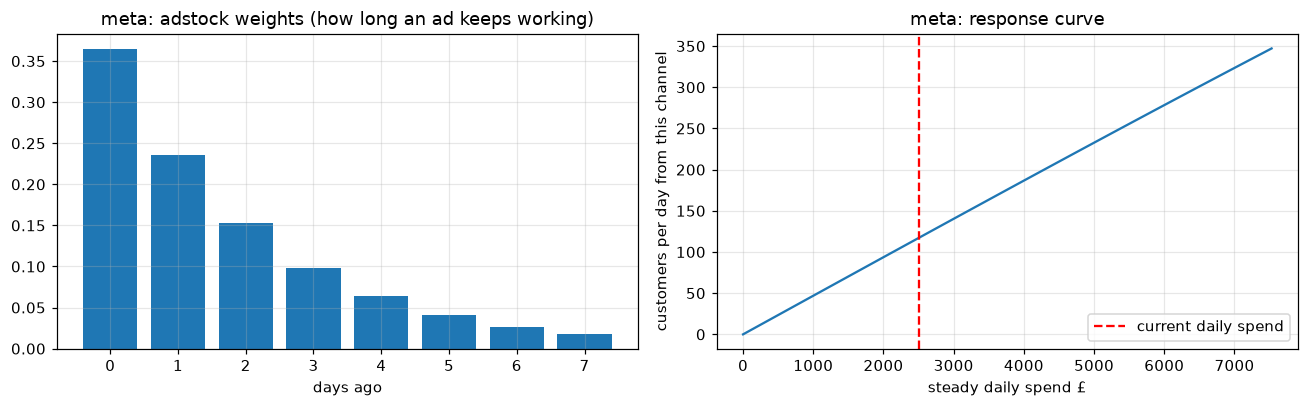

In [14]:
EX = "meta"
c = CHANNELS.index(EX)
P_mean = {k: P[k].mean(axis=0, keepdims=True) for k in ("alpha", "lam", "beta")}
P_mean.update(ch_scale=P["ch_scale"], tgt_scale=P["tgt_scale"], l_max=P["l_max"])
a, lam, beta = P_mean["alpha"][0, c], P_mean["lam"][0, c], P_mean["beta"][0, c]
L = P["l_max"]

print(f"Posterior means for {EX}: alpha (carry-over) = {a:.3f}, lambda (saturation speed) = {lam:.3f}, beta (strength) = {beta:.3f}")
print(f"Max daily {EX} spend in the data (the 'scale') = £{P['ch_scale'][c]:,.0f}; target scale = {P['tgt_scale']:.0f} customers")

weights = a ** np.arange(L); weights = weights / weights.sum()
print("\nAdstock weights (share of today's effect that comes from spend 0, 1, 2, ... days ago):")
print(pd.Series(weights.round(3), index=[f"{j} d ago" for j in range(L)]).to_string())

# step by step for the last 8 days of the data
spend_all = df[CHANNELS].to_numpy()
x = spend_all / P["ch_scale"]
ad = adstock_np(x, P_mean["alpha"], L)[0]
sat = saturation_np(ad[None], P_mean["lam"])[0]
cust = P_mean["beta"][0] * sat * P["tgt_scale"]
steps = pd.DataFrame({
    "date": df["date"].tail(8).dt.date.to_numpy(),
    "1. spend £": spend_all[-8:, c].round(0),
    "2. spend / max": x[-8:, c].round(3),
    "3. after adstock": ad[-8:, c].round(3),
    "4. after saturation": sat[-8:, c].round(3),
    "5. x beta x scale = customers": cust[-8:, c].round(1),
})
display(steps)

# the business question for this channel: +20% for 30 days
vec = base_daily.to_numpy().copy(); vec[c] *= 1.20
d_all = delta_customers(P, vec)                    # all posterior draws
d_mean_params = delta_customers(P_mean, vec)[0]    # using only the average parameters
extra_spend = base_daily[EX] * 0.20 * HORIZON
print(f"\n{EX} +20% for {HORIZON} days: extra spend £{extra_spend:,.0f}")
print(f"  extra customers (average over all draws): {d_all.mean():,.0f}  (90% range {np.percentile(d_all, 5):,.0f} to {np.percentile(d_all, 95):,.0f})")
print(f"  extra customers from the average parameters: {d_mean_params:,.0f}  (higher: the parameters are correlated, so averaging them first gives an unrealistic mix)")
print(f"  cost per extra customer = £{extra_spend:,.0f} / {d_all.mean():,.0f} = £{extra_spend / d_all.mean():,.1f}  -> {'below' if extra_spend / d_all.mean() <= CPA_TARGET else 'ABOVE'} the £{CPA_TARGET:.0f} target")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(range(L), weights); axes[0].set_xlabel("days ago"); axes[0].set_title(f"{EX}: adstock weights (how long an ad keeps working)")
grid = np.linspace(0, 3 * base_daily[EX], 100)
curve = beta * np.tanh(lam * (grid / P["ch_scale"][c]) / 2) * P["tgt_scale"]
axes[1].plot(grid, curve); axes[1].axvline(base_daily[EX], color="red", ls="--", label="current daily spend")
axes[1].set_xlabel("steady daily spend £"); axes[1].set_ylabel("customers per day from this channel")
axes[1].set_title(f"{EX}: response curve"); axes[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/04_worked_example_{EX}.png"); plt.show()

- Meta's carry-over is 0.65. Today's spend gives 36.5% of the effect, yesterday's 23.6%, the day before 15.2%. It is mostly gone within a week.
- Why the curve is straight: today's Meta spend (about £2.5k a day) is only 13% of its Black Friday peak (£19k), so we sit on the early, almost straight part of the curve. Extra money still pays at nearly the same rate.
- +£15k over 30 days brings about 526 extra customers (90% range 488-566), roughly £28.6 each, under the £40 limit.
- A trap I avoided: averaging the parameters first gives a more optimistic figure (664 customers). Meta's parameters are correlated, so averaging them destroys that connection. The headline uses the full posterior (526).
- This is a model estimate, not a promise.

## 8. Independent checks

In [15]:
# --- inputs for the checks ---
EX = "meta"
c = CHANNELS.index(EX)
L = P["l_max"]
base_vec = base_daily.to_numpy()
vec = base_vec.copy()
vec[c] *= 1.20                       # the change we test: Meta +20% for 30 days

# (a) same plan against itself must give exactly zero change
d_self = delta_customers(P, base_vec, base_vec)
print(f"(a) Baseline vs itself: max |change| = {np.abs(d_self).max():.12f} customers ->",
      "PASS" if np.abs(d_self).max() < 1e-9 else "FAIL")

# (b) manual recalculation of one change, written with plain Python loops (no vectorised code)
def manual_customers(daily_spend_list, a, lam, beta, ch_scale, tgt_scale, l_max):
    w = [a ** k for k in range(l_max)]
    tot_w = sum(w)
    w = [v / tot_w for v in w]
    out = []
    for t in range(len(daily_spend_list)):
        ad = sum(w[k] * daily_spend_list[t - k] / ch_scale for k in range(l_max) if t - k >= 0)
        sat = (1 - math.exp(-lam * ad)) / (1 + math.exp(-lam * ad))
        out.append(beta * sat * tgt_scale)
    return out

s = 0                                                     # one real posterior draw (not the average parameters)
a_s, lam_s, beta_s = P["alpha"][s, c], P["lam"][s, c], P["beta"][s, c]

hist_c = list(hist[:, c])
base_list = [float(base_daily[EX])] * HORIZON
plus_list = [float(base_daily[EX]) * 1.20] * HORIZON
cb = manual_customers(hist_c + base_list, a_s, lam_s, beta_s, P["ch_scale"][c], P["tgt_scale"], L)[-HORIZON:]
cp = manual_customers(hist_c + plus_list, a_s, lam_s, beta_s, P["ch_scale"][c], P["tgt_scale"], L)[-HORIZON:]
manual_delta = sum(cp) - sum(cb)
manual_spend = sum(plus_list) - sum(base_list)
engine_delta = delta_customers(P, vec)[s]                 # the same draw in the vectorised engine

print(f"(b) Posterior draw #{s}, {EX} +20%: manual loops give {manual_delta:,.3f} extra customers "
      f"for £{manual_spend:,.0f} -> £{manual_spend / manual_delta:,.2f} each")
print(f"    vectorised engine gives {engine_delta:,.3f} ->",
      "PASS" if abs(manual_delta - engine_delta) < 1e-6 else "FAIL")
d_all = delta_customers(P, vec)
print(f"    Headline figure (average over ALL draws): {d_all.mean():,.0f} extra customers "
      f"-> £{manual_spend / d_all.mean():,.2f} each")

# (c) bigger and bigger Meta increases: does the cost per customer move?
rows = []
for pct in [0.10, 0.20, 0.40, 0.80]:
    v = base_vec.copy(); v[c] *= 1 + pct
    dd = delta_customers(P, v)
    sp = base_daily[EX] * pct * HORIZON
    rows.append({"Meta increase": f"+{pct:.0%}", "extra spend £": round(sp), "extra customers": round(dd.mean()),
                 "cost per extra customer £": round(sp / dd.mean(), 2)})
chk = pd.DataFrame(rows); display(chk)
rise = chk["cost per extra customer £"].iloc[-1] / chk["cost per extra customer £"].iloc[0] - 1
print(f"(c) cost per extra customer changes by {rise:.1%} between +10% and +80%:",
      "clear diminishing returns" if rise > 0.05 else "almost flat -> little diminishing returns visible for this channel in this range")

# (d) switching a channel off
v0 = base_vec.copy()
v0[c] = 0.0
lost = -delta_customers(P, v0)
print(f"(d) Switching {EX} off for {HORIZON} days loses about {lost.mean():,.0f} customers "
      f"(90% range {np.percentile(lost, 5):,.0f}-{np.percentile(lost, 95):,.0f}); "
      f"saving £{base_daily[EX] * HORIZON:,.0f} -> £{base_daily[EX] * HORIZON / lost.mean():,.1f} per customer lost")

(a) Baseline vs itself: max |change| = 0.000000000000 customers -> PASS
(b) Posterior draw #0, meta +20%: manual loops give 501.875 extra customers for £15,056 -> £30.00 each
    vectorised engine gives 501.875 -> PASS
    Headline figure (average over ALL draws): 526 extra customers -> £28.63 each


,Meta increase,extra spend £,extra customers,cost per extra customer £
0,+10%,7528,263,28.61
1,+20%,15056,526,28.63
2,+40%,30113,1050,28.67
3,+80%,60226,2093,28.77


(c) cost per extra customer changes by 0.6% between +10% and +80%: almost flat -> little diminishing returns visible for this channel in this range
(d) Switching meta off for 30 days loses about 2,645 customers (90% range 2,446-2,847); saving £75,282 -> £28.5 per customer lost


In [19]:
# Stress test: what does the NEXT £ cost at much larger spend? (far beyond normal, illustration only)
base_vec = base_daily.to_numpy()
mults_long = [1.1, 2.5, 5.0, 7.5]
rows = []
for i, ch in enumerate(CHANNELS):
    prev_m, prev_d = 1.0, 0.0
    for m in mults_long:
        v = base_vec.copy(); v[i] *= m
        d = delta_customers(P, v).mean()
        step_spend = base_daily[ch] * (m - prev_m) * HORIZON
        rows.append({"channel": ch, "spend vs now": f"{m}x",
                     "cost of this step £": round(step_spend / (d - prev_d), 1)})
        prev_m, prev_d = m, d
table = pd.DataFrame(rows).pivot(index="channel", columns="spend vs now", values="cost of this step £")
display(table.reindex(CHANNELS)[[f"{m}x" for m in mults_long]])
print("Note: 5x and 7.5x are far above normal spend (Meta 7.5x is about £18.8k/day, close to its Black Friday peak). Illustration, not a forecast.")

spend vs now,1.1x,2.5x,5.0x,7.5x
channel,,,,
bing,15.4,17.9,27.1,43.8
google,31.6,53.6,249.7,1912.1
meta,28.6,29.0,31.0,35.4
pinterest,33.3,36.9,51.0,78.0


Note: 5x and 7.5x are far above normal spend (Meta 7.5x is about £18.8k/day, close to its Black Friday peak). Illustration, not a forecast.


- Baseline vs itself gives exactly 0, and a hand-written loop (on one posterior draw) matches the vectorised engine to six decimals.
- Meta's cost barely moves from +10% to +80% (£28.61 to £28.77, +0.6%). That is not a bug: the same code makes Google bend sharply. Meta simply sits on the straight start of its curve.
- Far beyond today's spend (5-7.5x, the Black Friday zone) the step cost climbs for every channel: Google's explodes, Meta's climbs much more slowly. Pure extrapolation, so illustration only.
- Switching Meta off for 30 days loses about 2,645 customers (range 2,446-2,847) and saves £75k, or £28.5 per customer lost. Meta clearly matters.

## 9. Five spending plans (30 days)
Units used in this section, to avoid mixing them up:
- £ per day = daily spend level in a plan;
- £ over 30 days = total spend for the test window (daily x 30);
- new customers over 30 days = expected extra customers in that window (not £).

Proportional plans (+10%, +20%, -10%) scale every channel by the same percentage, so the mix stays the same. Plan 5 in this first version moves money from Pinterest to Bing. It is kept below for transparency and is replaced by the four-channel optimisation in section 10c.

,extra spend £ (30d),extra customers (mean),marginal cost £ per extra customer,P(cost < £40)
bing,994.33,64.39,15.44,0.99
google,6794.86,214.87,31.62,0.99
meta,7528.20,263.17,28.61,1.00
pinterest,1903.54,57.24,33.25,0.71


Cheapest extra customers: bing   |   most expensive: pinterest
Reallocation: move £127 per day (£3,807 over 30 days) from pinterest to bing


Scenario,1. Keep spend (baseline),2. +10% all channels,3. +20% all channels,4. -10% all channels,"5. Move £3,807 from pinterest to bing"
bing £,9943.25,10937.58,11931.90,8948.93,13750.33
google £,67948.60,74743.46,81538.32,61153.74,67948.60
meta £,75282.03,82810.23,90338.44,67753.83,75282.03
pinterest £,19035.42,20938.96,22842.50,17131.88,15228.34
Total spend £,172209.30,189430.23,206651.16,154988.37,172209.30
Change in spend £,0.00,17220.93,34441.86,-17220.93,-0.00
New customers (expected),12558.00,13157.67,13741.06,11942.02,12681.78
Change in customers (mean),0.00,599.67,1183.06,-615.98,123.78
Change 5%,0.00,557.47,1098.48,-662.55,0.45
Change 95%,0.00,641.31,1261.60,-568.36,244.89


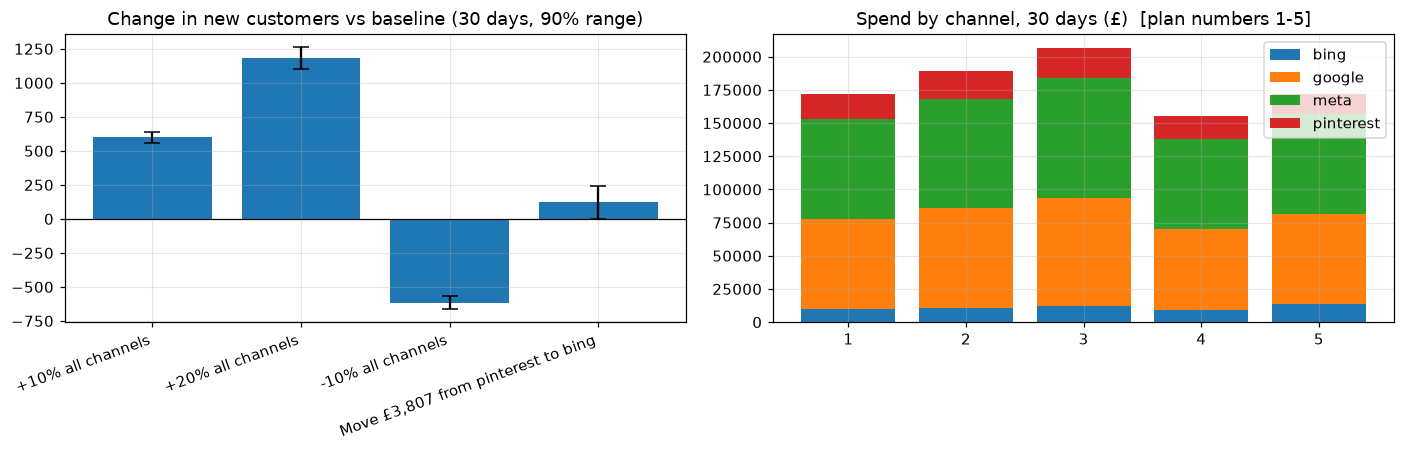

In [21]:
def channel_marginal_cpa(P, step=0.10):
    base = base_daily.to_numpy()
    out = {}
    for i, ch in enumerate(CHANNELS):
        v = base.copy(); v[i] *= 1 + step
        d = delta_customers(P, v, base)
        dspend = base[i] * step * HORIZON
        with np.errstate(divide="ignore", invalid="ignore"):
            p_ok = np.mean((d > 0) & (dspend / np.where(d > 0, d, np.nan) <= CPA_TARGET))
        out[ch] = {"extra spend £ (30d)": dspend, "extra customers (mean)": d.mean(),
                   "marginal cost £ per extra customer": dspend / d.mean(), "P(cost < £40)": p_ok}
    return pd.DataFrame(out).T

marg = channel_marginal_cpa(P)
display(marg.round(2))
best_ch = marg["marginal cost £ per extra customer"].astype(float).idxmin()
worst_ch = marg["marginal cost £ per extra customer"].astype(float).idxmax()
MOVE_SHARE = 0.20            # at most this share of the most expensive channel's budget is moved
MAX_RECEIVER_MULT = 1.5      # the receiving channel may grow at most to 1.5x its current spend

base = base_daily.to_numpy()
iw, ib = CHANNELS.index(worst_ch), CHANNELS.index(best_ch)
moved = min(base[iw] * MOVE_SHARE, base[ib] * (MAX_RECEIVER_MULT - 1))     # £ per day
realloc = base.copy()
realloc[iw] -= moved
realloc[ib] += moved
assert abs(realloc.sum() - base.sum()) < 1e-6, "reallocation must keep the total budget unchanged"
print(f"Cheapest extra customers: {best_ch}   |   most expensive: {worst_ch}")
print(f"Reallocation: move £{moved:,.0f} per day (£{moved * HORIZON:,.0f} over {HORIZON} days) from {worst_ch} to {best_ch}")

SCEN = {
    "1. Keep spend (baseline)": base,
    "2. +10% all channels": base * 1.10,
    "3. +20% all channels": base * 1.20,
    "4. -10% all channels": base * 0.90,
    f"5. Move £{moved * HORIZON:,.0f} from {worst_ch} to {best_ch}": realloc,
}
BASE_KEY = "1. Keep spend (baseline)"

def evaluate(P, scen, base_key):
    base_vec = scen[base_key]
    base_spend = base_vec.sum() * HORIZON
    rows, draws = [], {}
    for name, vec in scen.items():
        d = delta_customers(P, vec, base_vec)
        dspend = vec.sum() * HORIZON - base_spend
        draws[name] = d
        row = {"Scenario": name}
        for ch, v in zip(CHANNELS, vec):
            row[f"{ch} £"] = v * HORIZON
        row["Total spend £"] = vec.sum() * HORIZON
        row["Change in spend £"] = dspend
        row["New customers (expected)"] = base_new_30d + d.mean()
        row["Change in customers (mean)"] = d.mean()
        row["Change 5%"], row["Change 95%"] = np.percentile(d, [5, 95])
        with np.errstate(divide="ignore", invalid="ignore"):
            if dspend > 1e-9:
                row["Cost per extra customer £"] = dspend / d.mean() if d.mean() > 0 else np.nan
                row["P(cost < £40)"] = np.mean((d > 0) & (dspend / d <= CPA_TARGET))
            elif dspend < -1e-9:
                row["Money saved £"] = -dspend
                row["Customers lost"] = -d.mean()
                row["Saved per customer lost £"] = (-dspend) / (-d.mean()) if d.mean() < 0 else np.nan
                row["P(saved per lost customer > £40)"] = np.mean((d < 0) & ((-dspend) / (-d) > CPA_TARGET))
            elif name != base_key:
                row["P(more customers than baseline)"] = np.mean(d > 0)
        rows.append(row)
    return pd.DataFrame(rows).set_index("Scenario"), draws

scen_table, scen_draws = evaluate(P, SCEN, BASE_KEY)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
display(scen_table.round(2).T)
scen_table.round(2).to_csv(f"{OUT_DIR}/scenario_table.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
names = list(SCEN.keys())[1:]
means = [scen_draws[n].mean() for n in names]
err_lo = [scen_draws[n].mean() - np.percentile(scen_draws[n], 5) for n in names]
err_hi = [np.percentile(scen_draws[n], 95) - scen_draws[n].mean() for n in names]
axes[0].bar(range(len(names)), means, yerr=[err_lo, err_hi], capsize=5, color="tab:blue")
axes[0].set_xticks(range(len(names))); axes[0].set_xticklabels([n.split(". ")[1] for n in names], rotation=20, ha="right")
axes[0].axhline(0, color="black", lw=0.8); axes[0].set_title("Change in new customers vs baseline (30 days, 90% range)")
bottom = np.zeros(len(SCEN))
for i, ch in enumerate(CHANNELS):
    vals = np.array([v[i] * HORIZON for v in SCEN.values()])
    axes[1].bar(range(len(SCEN)), vals, bottom=bottom, label=ch); bottom += vals
axes[1].set_xticks(range(len(SCEN))); axes[1].set_xticklabels([n.split(". ")[0] for n in SCEN])
axes[1].set_title("Spend by channel, 30 days (£)  [plan numbers 1-5]"); axes[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/05_scenarios.png"); plt.show()

Reading the first version's numbers, with units made explicit:
- One channel at a time (+10%). Every channel costs less than £40 per extra customer: Bing £15, Meta £29, Google £32, Pinterest £33. Pinterest is the shakiest (only 71% of model draws stay under £40).
- Plans 2 and 3: +10% across the board adds about 600 new customers over 30 days (range 557-641) for about £17k of extra spend, roughly £28.7 each; +20% adds about 1,183 (1,098-1,262) for about £34k, roughly £29.1 each.
- Plan 4: -10% saves about £17k over 30 days and loses about 616 customers over 30 days, so £28 saved per customer lost. Under £40, so cutting is not attractive.
- Plan 5 (simple rule): moving £3,807 over 30 days (which is £127 per day) from Pinterest to Bing gains about 124 customers over 30 days (+1%; range 0-245). 
- Bing is the cheapest but tiny. Its reallocation is capped at 1.5x because the data has not seen much more.

## 10. How far can each channel go? Response curves and the £40 ceiling

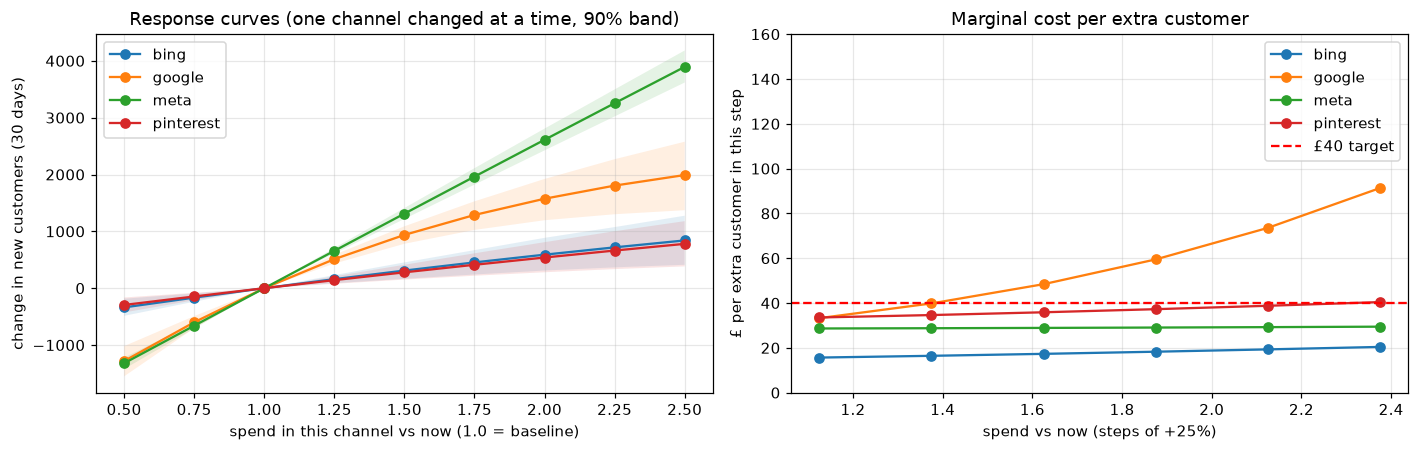

,daily spend £,marginal cost £ (+10% step),P(cost < £40),share of max effect already reached,spend ceiling for £40
bing,331.0,15.4,0.99,0.22,above 2.50x (not reached)
google,2265.0,31.6,0.99,0.52,about 1.50x current spend
meta,2509.0,28.6,1.00,0.07,above 2.50x (not reached)
pinterest,635.0,33.3,0.71,0.18,about 2.25x current spend


In [22]:
mults = np.round(np.arange(0.5, 2.51, 0.25), 2)
curves = {}
for i, ch in enumerate(CHANNELS):
    rows = []
    for m in mults:
        v = base.copy(); v[i] *= m
        d = delta_customers(P, v, base)
        rows.append({"mult": m, "extra_spend": base[i] * (m - 1) * HORIZON,
                     "d_mean": d.mean(), "d_lo": np.percentile(d, 5), "d_hi": np.percentile(d, 95)})
    curves[ch] = pd.DataFrame(rows)

def ceiling(cdf):
    up = cdf[cdf["mult"] >= 1.0].reset_index(drop=True)
    for k in range(1, len(up)):
        step_spend = up.loc[k, "extra_spend"] - up.loc[k - 1, "extra_spend"]
        step_cust = up.loc[k, "d_mean"] - up.loc[k - 1, "d_mean"]
        if step_cust <= 0 or step_spend / step_cust > CPA_TARGET:
            return "already above £40 at the margin" if k == 1 else f"about {up.loc[k - 1, 'mult']:.2f}x current spend"
    return f"above {up['mult'].max():.2f}x (not reached)"

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ch in CHANNELS:
    cdf = curves[ch]
    axes[0].plot(cdf["mult"], cdf["d_mean"], marker="o", label=ch)
    axes[0].fill_between(cdf["mult"], cdf["d_lo"], cdf["d_hi"], alpha=0.12)
    up = cdf[cdf["mult"] >= 1.0].reset_index(drop=True)
    step_spend = up["extra_spend"].diff(); step_cust = up["d_mean"].diff()
    axes[1].plot((up["mult"] - 0.125)[1:], (step_spend / step_cust)[1:], marker="o", label=ch)
axes[0].set_xlabel("spend in this channel vs now (1.0 = baseline)"); axes[0].set_ylabel("change in new customers (30 days)")
axes[0].set_title("Response curves (one channel changed at a time, 90% band)"); axes[0].legend()
axes[1].axhline(CPA_TARGET, color="red", ls="--", label=f"£{CPA_TARGET:.0f} target")
axes[1].set_xlabel("spend vs now (steps of +25%)"); axes[1].set_ylabel("£ per extra customer in this step")
axes[1].set_title("Marginal cost per extra customer"); axes[1].set_ylim(0, 4 * CPA_TARGET); axes[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/06_response_curves.png"); plt.show()

sat_share = np.median(np.tanh(P["lam"] * (base / P["ch_scale"]) / 2), axis=0)
channel_table = pd.DataFrame({
    "daily spend £": base_daily.round(0),
    "marginal cost £ (+10% step)": marg["marginal cost £ per extra customer"].astype(float).round(1),
    "P(cost < £40)": marg["P(cost < £40)"].astype(float).round(2),
    "share of max effect already reached": pd.Series(sat_share, index=CHANNELS).round(2),
    "spend ceiling for £40": pd.Series({ch: ceiling(curves[ch]) for ch in CHANNELS}),
})
display(channel_table)
channel_table.to_csv(f"{OUT_DIR}/channel_table.csv")

## 10a. Cost per extra customer with ranges, and the £40 ceiling
The earlier cost figures were point estimates. Here each one carries a 90% range from the posterior draws.
Read the cost range this way: the low end uses the 95th-percentile customer gain, the high end uses the 5th-percentile gain.

,cpa_mean,cpa_low,cpa_high,p_below_40
channel,,,,
bing,15.44,10.68,27.94,0.99
google,31.62,27.72,37.31,0.99
meta,28.61,26.60,30.84,1.00
pinterest,33.25,22.77,60.33,0.71


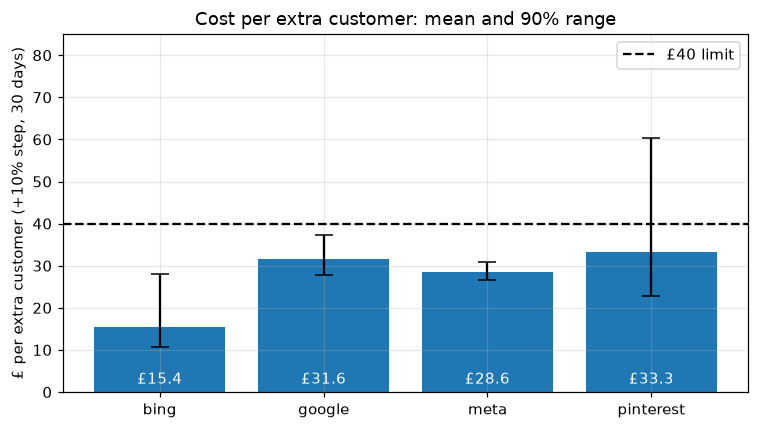

In [17]:
# --- 10a.1 Cost per extra customer (+10% step) with a 90% range ---------------------------
def cpa_with_range(P, step=0.10):
    rows = []
    for i, ch in enumerate(CHANNELS):
        v = base.copy(); v[i] *= 1 + step            # increase ONLY this channel
        d = delta_customers(P, v, base)               # 1000 draws = 1000 plausible "versions of the world"
        dspend = base[i] * step * HORIZON             # extra £ spent over 30 days
        p5, p95 = np.percentile(d, [5, 95])
        rows.append({
            "channel": ch,
            "cpa_mean": dspend / d.mean(),                                  # headline value
            "cpa_low": dspend / p95,                                        # best realistic case (many customers)
            "cpa_high": dspend / p5 if p5 > 0 else np.inf,                  # worst realistic case (few customers)
            "p_below_40": np.mean((d > 0) & (dspend / np.where(d > 0, d, np.nan) <= CPA_TARGET)),
        })
    return pd.DataFrame(rows).set_index("channel")

cpa_tbl = cpa_with_range(P)
display(cpa_tbl.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(CHANNELS))
hi_clip = np.minimum(cpa_tbl["cpa_high"].to_numpy(), 80)           # clip very large upper ends so the chart stays readable
ax.bar(x, cpa_tbl["cpa_mean"], color="tab:blue",
       yerr=[cpa_tbl["cpa_mean"] - cpa_tbl["cpa_low"], hi_clip - cpa_tbl["cpa_mean"]], capsize=6)
ax.axhline(CPA_TARGET, color="black", ls="--", label=f"£{CPA_TARGET:.0f} limit")
for xi, (m, h) in enumerate(zip(cpa_tbl["cpa_mean"], cpa_tbl["cpa_high"])):
    ax.text(xi, 2, f"£{m:.1f}", ha="center", color="white", fontsize=10)
    if h > 80: ax.text(xi, 78, "range > £80", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(CHANNELS); ax.set_ylim(0, 85)
ax.set_ylabel("£ per extra customer (+10% step, 30 days)")
ax.set_title("Cost per extra customer: mean and 90% range"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/07_cpa_with_ranges.png", dpi=150); plt.show()

- Meta: the line is nearly straight and the cost of the next step stays near £29 all the way to 2.5x, with the narrowest band of the four. It looks like the best place to scale, but this assumes that the model experiences virtually no saturation.
- Google: bends first. It has already used 52% of its maximum effect, and extra money passes £40 at roughly 1.5x today's spend (about £3.4k a day).
- Bing: cheapest (£15) and still under £40 beyond 2.5x, but small in absolute terms.
- Pinterest: reaches £40 at about 2.25x today's spend. Small, and the least certain (71% under £40).
- A channel is a safe place to add money only if its whole 90% cost range stays below £40. Pinterest breaches it (upper bound £60.33), and Google is very close to the limit (ceiling at 1.5x).

## 10b. Does the answer change under reasonable assumption changes? (refit)
Four alternative models are refitted on all data. Each one checks a different assumption:
1. `l_max` 8 -> 14: longer ad memory (the default may cut off long carry-over).
2. `yearly_seasonality` 2 -> 3.
3. `yearly_seasonality` 2 -> 4: more flexible seasonal wave.
4. HillSaturation (S-shaped) instead of LogisticSaturation. The Hill `slope` shows whether returns are first increasing (slope > 1) or diminishing from the start (slope < 1). This also addresses the question in the brief about whether extra spend becomes more or less effective.

For each variant I recompute the same decisions: cost per extra customer by channel, and the Meta +20% test.
Each refit takes several minutes.

In [ ]:
def fit_variant(data, l_max=8, yearly_seasonality=2, saturation="logistic"):
    data = data.reset_index(drop=True)
    X = data[MODEL_COLS]; y = data["new_customers"].rename("y")
    sat = LogisticSaturation() if saturation == "logistic" else HillSaturation()
    mmm = MMM(date_column="date", channel_columns=CHANNELS, control_columns=CONTROLS,
              adstock=GeometricAdstock(l_max=l_max), saturation=sat, yearly_seasonality=yearly_seasonality)
    mmm.fit(X=X, y=y, chains=CHAINS, draws=DRAWS, tune=TUNE, target_accept=0.9, random_seed=SEED)
    f = Fit(mmm=mmm, data=data, l_max=l_max, tgt_scale=float(y.max()), ch_scale=X[CHANNELS].max().to_numpy())
    f.sat = saturation                 # remember which saturation curve this model uses
    return f

def get_params_v(fit, n_keep=N_KEEP, seed=SEED):
    post = fit.mmm.idata.posterior
    names = [("alpha", "adstock_alpha"), ("beta", "saturation_beta")]
    # logistic has one curve parameter (lam); Hill has slope and kappa
    names += [("lam", "saturation_lam")] if fit.sat == "logistic" else [("slope", "saturation_slope"), ("kappa", "saturation_kappa")]
    out = {}
    for key, prefix in names:
        da = pick(post, prefix); order = [str(c) for c in da.coords["channel"].values]
        arr = np.asarray(da.transpose("chain", "draw", "channel").values)
        out[key] = arr.reshape(-1, arr.shape[-1])[:, [order.index(c) for c in CHANNELS]]
    total = out["alpha"].shape[0]
    sel = np.sort(np.random.default_rng(seed).choice(total, size=min(n_keep, total), replace=False))
    for k in list(out): out[k] = out[k][sel]
    out.update(sel=sel, ch_scale=fit.ch_scale, tgt_scale=fit.tgt_scale, l_max=fit.l_max, sat=fit.sat)
    return out

def saturation_v(a, Pv):
    if Pv["sat"] == "logistic":
        return np.tanh(Pv["lam"][:, None, :] * a / 2.0)
    s, k = Pv["slope"][:, None, :], Pv["kappa"][:, None, :]          # Hill: x^s / (k^s + x^s)
    return a ** s / (k ** s + a ** s)

def contributions_v(spend, Pv):
    x = spend / Pv["ch_scale"]
    a = adstock_np(x, Pv["alpha"], Pv["l_max"])
    return Pv["beta"][:, None, :] * saturation_v(a, Pv) * Pv["tgt_scale"]

def delta_v(Pv, vec, base_vec):
    def tot(v):
        plan = np.tile(v, (HORIZON, 1))
        return contributions_v(np.vstack([hist, plan]), Pv)[:, -HORIZON:, :].sum(axis=(1, 2))
    return tot(vec) - tot(base_vec)

def check_engine_v(fit, Pv, tol=0.01):          # same check as section 6: my NumPy == the library
    lib, _ = library_contributions(fit, Pv)
    mine = contributions_v(fit.data[CHANNELS].to_numpy(), Pv)
    rel = np.abs(mine - lib).max() / lib.mean()
    print(f"  engine check: difference {rel:.4%} ->", "PASS" if rel < tol else "MISMATCH, DO NOT USE")
    return rel

def summarise_variant(name, fit):
    summ = diagnostics(fit)
    Pv = get_params_v(fit); check_engine_v(fit, Pv)
    row = {}
    for i, ch in enumerate(CHANNELS):
        v = base.copy(); v[i] *= 1.10
        d = delta_v(Pv, v, base); dsp = base[i] * 0.10 * HORIZON
        row[f"CPA {ch}"] = round(dsp / d.mean(), 1)
    vm = base.copy(); vm[CHANNELS.index("meta")] *= 1.20
    dm = delta_v(Pv, vm, base); dsp_m = base[CHANNELS.index("meta")] * 0.20 * HORIZON
    p5, p95 = np.percentile(dm, [5, 95])
    row.update({"Meta +20%: extra customers (30d)": round(dm.mean()),
                "Meta +20% range": f"{p5:.0f} to {p95:.0f}",
                "Meta +20% £/customer": round(dsp_m / dm.mean(), 1),
                "max r_hat": round(float(summ["r_hat"].max()), 3)})
    hill_info = {}
    if Pv["sat"] == "hill":
        sl = Pv["slope"]
        hill_info = {"Hill slope median": {c: round(float(np.median(sl[:, i])), 2) for i, c in enumerate(CHANNELS)},
                     "P(slope > 1)": {c: round(float(np.mean(sl[:, i] > 1)), 2) for i, c in enumerate(CHANNELS)}}
    return {"variant": name, **row}, Pv, hill_info

VARIANTS = {
    "0. Base (l_max=8, yearly=2, Logistic)": dict(),
    "1. l_max=14":                           dict(l_max=14),
    "2. yearly_seasonality=3":               dict(yearly_seasonality=3),
    "3. yearly_seasonality=4":               dict(yearly_seasonality=4),
    "4. HillSaturation (S-shaped)":          dict(saturation="hill"),
}
variant_rows, variant_P, variant_hill, variant_fit = [], {}, {}, {}      
for name, kw in VARIANTS.items():
    print("\n=====", name)
    fv = fit_variant(df, **kw)
    variant_fit[name] = fv                                              
    row, Pv, hill_info = summarise_variant(name, fv)
    variant_rows.append(row); variant_P[name] = Pv
    if hill_info: variant_hill[name] = hill_info

robust = pd.DataFrame(variant_rows).set_index("variant")
display(robust)
robust.to_csv(f"{OUT_DIR}/robustness_table.csv")
for name, info in variant_hill.items():
    print(name)
    display(pd.DataFrame(info))


===== 0. Base (l_max=8, yearly=2, Logistic)


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [adstock_alpha, saturation_lam, saturation_beta, gamma_fourier, gamma_control, intercept_contribution, y_sigma]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 216 seconds.


Output()

max r_hat  = 1.002   (want < 1.01)
min ESS    = 1476    (want > 400)
divergences= 0      (want 0 or very few)
  engine check: difference 0.0000% -> PASS

===== 1. l_max=14


... (19 outputs left out)

max r_hat  = 1.575   (want < 1.01)
min ESS    = 7    (want > 400)
divergences= 948      (want 0 or very few)
  engine check: difference 0.0000% -> PASS


,CPA bing,CPA google,CPA meta,CPA pinterest,Meta +20%: extra customers (30d),Meta +20% range,Meta +20% £/customer,max r_hat
variant,,,,,,,,
"0. Base (l_max=8, yearly=2, Logistic)",15.4,31.6,28.6,33.3,526,488 to 566,28.6,1.002
1. l_max=14,15.1,32.3,28.5,36.1,528,490 to 567,28.5,1.005
2. yearly_seasonality=3,20.1,38.8,29.9,26.6,503,466 to 540,30.0,1.002
3. yearly_seasonality=4,22.9,38.5,29.5,28.4,509,475 to 545,29.6,1.003
4. HillSaturation (S-shaped),25.0,34.8,33.8,40.2,470,420 to 525,32.1,1.575


4. HillSaturation (S-shaped)


,Hill slope median,P(slope > 1)
bing,0.42,0.40
google,0.16,0.09
meta,2.56,1.00
pinterest,0.92,0.23


In [47]:
fit_hill = fv
summ = az.summary(fit_hill.mmm.idata, var_names=["saturation_slope", "saturation_kappa", "saturation_beta"])
display(summ.sort_values("r_hat", ascending=False))

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
saturation_slope[bing],1,1.06,0.0074,2.9,7,5,1.57,0.26,0.027
saturation_slope[pinterest],0.78,0.5,0.034,1.7,142,120,1.54,0.042,0.065
saturation_beta[bing],0.6,0.6,0.037,1.6,8,13,1.45,0.29,0.13
saturation_kappa[pinterest],1.59,0.8,0.29,3,178,119,1.36,0.048,0.1
saturation_slope[meta],2.5,0.38,1.9,3,10,16,1.30,0.12,0.014
saturation_slope[google],0.4,0.4,0.081,1.2,10,31,1.30,0.11,0.055
saturation_beta[google],0.8,0.54,0.14,1.5,10,48,1.30,0.19,0.012
saturation_kappa[meta],0.39,0.07,0.33,0.51,11,52,1.28,0.018,0.0056
saturation_beta[meta],0.22,0.046,0.18,0.31,14,74,1.21,0.011,0.0033
saturation_kappa[google],1,0.81,0.017,2.3,14,26,1.19,0.2,0.016


HillSaturation (S-shaped): first attempt did not converge.
With default priors the sampler gave max r-hat 1.575, min ESS 7 and 948 divergences. The worst parameters were `slope` and `kappa` (for Bing, `slope` ranged from 0.007 to 2.9), so the data did not pin down the curve shape.

Second attempt: three changes at once
- `slope`: HalfNormal(1.5) → Gamma(mu=1.0, sigma=0.5). Centred on 1 (no S-shape assumed either way), so it allows both falling (<1) and rising (>1) returns.
- `kappa`: HalfNormal(1.5) → Gamma(mu=0.8, sigma=0.5). This is a judgement call: it only keeps `kappa` away from zero and is not based on the data.
- `tune` 1000 → 2000 and `target_accept` 0.9 → 0.95 (the sampler warning advised raising `target_accept`).
- `beta` was left at its default.

I changed all three at once, so I cannot say which one helped.

In [ ]:
try:
    from pymc_marketing.prior import Prior
except ImportError:
    from pymc_extras.prior import Prior     

def fit_variant(data, l_max=8, yearly_seasonality=2, saturation="logistic",
                hill_priors=None, tune=TUNE, target_accept=0.9):
    data = data.reset_index(drop=True)
    X = data[MODEL_COLS]; y = data["new_customers"].rename("y")
    sat = LogisticSaturation() if saturation == "logistic" else HillSaturation(priors=hill_priors)
    mmm = MMM(date_column="date", channel_columns=CHANNELS, control_columns=CONTROLS,
              adstock=GeometricAdstock(l_max=l_max), saturation=sat, yearly_seasonality=yearly_seasonality)
    mmm.fit(X=X, y=y, chains=CHAINS, draws=DRAWS, tune=tune, target_accept=target_accept, random_seed=SEED)
    f = Fit(mmm=mmm, data=data, l_max=l_max, tgt_scale=float(y.max()), ch_scale=X[CHANNELS].max().to_numpy())
    f.sat = saturation
    return f

In [ ]:
hill_priors = {
    "slope": Prior("Gamma", mu=1.0, sigma=0.5, dims="channel"),
    "kappa": Prior("Gamma", mu=0.8, sigma=0.5, dims="channel"),
}
fit_hill2 = fit_variant(df, saturation="hill", hill_priors=hill_priors, tune=2000, target_accept=0.95)
fit_hill2.mmm.idata.to_netcdf(f"{OUT_DIR}/idata_hill_priors.nc")

summ2 = az.summary(fit_hill2.mmm.idata, var_names=["saturation_slope", "saturation_kappa", "saturation_beta"])
display(summ2.sort_values("r_hat", ascending=False))

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [saturation_kappa, adstock_alpha, saturation_slope, saturation_beta, gamma_fourier, gamma_control, intercept_contribution, y_sigma]


Output()

Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 2072 seconds.
There were 61 divergences after tuning. Increase `target_accept` or reparameterize.
Chain 3 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.


Output()

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
saturation_kappa[meta],0.438,0.09,0.34,0.6,1241,1005,1.00,0.0033,0.0055
saturation_beta[meta],0.251,0.058,0.19,0.35,1223,1051,1.00,0.002,0.003
saturation_slope[meta],2.24,0.31,1.7,2.7,1437,1081,1.00,0.0081,0.0055
saturation_beta[pinterest],0.067,0.043,0.026,0.13,2107,2138,1.00,0.00093,0.0023
saturation_beta[google],0.34,0.19,0.12,0.71,1000,1083,1.00,0.0067,0.0071
saturation_kappa[pinterest],0.94,0.54,0.28,1.9,2507,2314,1.00,0.01,0.0096
saturation_beta[bing],0.077,0.09,0.022,0.17,2120,1993,1.00,0.0024,0.011
saturation_slope[bing],1,0.58,0.27,2.1,1795,1716,1.00,0.013,0.01
saturation_kappa[bing],1.04,0.63,0.26,2.2,2598,2135,1.00,0.012,0.013
saturation_slope[google],0.53,0.32,0.17,1.1,1010,1094,1.00,0.0088,0.0069


In [46]:
row, Pv_hill2, hill_info2 = summarise_variant("4. Hill (narrower priors)", fit_hill2)
display(pd.DataFrame(hill_info2))

max r_hat  = 1.005   (want < 1.01)
min ESS    = 1000    (want > 400)
divergences= 61      (want 0 or very few)
  engine check: difference 0.0000% -> PASS


,Hill slope median,P(slope > 1)
bing,0.86,0.40
google,0.45,0.11
meta,2.22,1.00
pinterest,0.88,0.38


This time model is converged according to r_hat and ESS, but with 1.5% divergent transitions.

In [48]:
# --- 10b.2 Do the headline conclusions survive all variants? -------------------------------
# Step 1: replace the old Hill row (did not converge) with the new one (narrower priors)
row_new, Pv_hill2, hill_info2 = summarise_variant("4. Hill (narrower priors)", fit_hill2)   # recalculates the numbers from the new model (takes about 2 seconds)
robust = robust[~robust.index.str.startswith("4.")]                                         # remove every old row whose name starts with "4."
robust = pd.concat([robust, pd.DataFrame([row_new]).set_index("variant")])                  # add the new row at the bottom
variant_P["4. Hill (narrower priors)"] = Pv_hill2                                           # later cells (reallocation stability) use this dictionary
variant_P.pop("4. HillSaturation (S-shaped)", None)                                         # and must not see the old Hill model
robust.to_csv(f"{OUT_DIR}/robustness_table.csv")
display(robust)

# Step 2: the three checks, now on the converged versions
cols = [f"CPA {c}" for c in CHANNELS]
below_40 = (robust[cols] < CPA_TARGET).all(axis=1)
rank_same = robust[cols].rank(axis=1).eq(robust[cols].rank(axis=1).iloc[0]).all(axis=1)
meta_volume_ok = robust["Meta +20%: extra customers (30d)"] > 400
converged = robust["max r_hat"] < 1.01
print("Sampler converged (max r_hat < 1.01):\n", converged.to_string())
print("\nAll four channels below £40 in this variant:\n", below_40.to_string())
print("\nSame cost ranking of channels as the base model:\n", rank_same.to_string())
print("\nMeta +20% gives more than 400 extra customers over 30 days:\n", meta_volume_ok.to_string())

max r_hat  = 1.005   (want < 1.01)
min ESS    = 1000    (want > 400)
divergences= 61      (want 0 or very few)
  engine check: difference 0.0000% -> PASS


,CPA bing,CPA google,CPA meta,CPA pinterest,Meta +20%: extra customers (30d),Meta +20% range,Meta +20% £/customer,max r_hat
variant,,,,,,,,
"0. Base (l_max=8, yearly=2, Logistic)",15.4,31.6,28.6,33.3,526,488 to 566,28.6,1.002
1. l_max=14,15.1,32.3,28.5,36.1,528,490 to 567,28.5,1.005
2. yearly_seasonality=3,20.1,38.8,29.9,26.6,503,466 to 540,30.0,1.002
3. yearly_seasonality=4,22.9,38.5,29.5,28.4,509,475 to 545,29.6,1.003
4. Hill (narrower priors),19.0,34.8,32.2,36.8,485,433 to 536,31.0,1.005


Sampler converged (max r_hat < 1.01):
 variant
0. Base (l_max=8, yearly=2, Logistic)    True
1. l_max=14                              True
2. yearly_seasonality=3                  True
3. yearly_seasonality=4                  True
4. Hill (narrower priors)                True

All four channels below £40 in this variant:
 variant
0. Base (l_max=8, yearly=2, Logistic)    True
1. l_max=14                              True
2. yearly_seasonality=3                  True
3. yearly_seasonality=4                  True
4. Hill (narrower priors)                True

Same cost ranking of channels as the base model:
 variant
0. Base (l_max=8, yearly=2, Logistic)     True
1. l_max=14                               True
2. yearly_seasonality=3                  False
3. yearly_seasonality=4                  False
4. Hill (narrower priors)                 True

Meta +20% gives more than 400 extra customers over 30 days:
 variant
0. Base (l_max=8, yearly=2, Logistic)    True
1. l_max=14                 

In [52]:
# --- 10b.3 What does the NEXT £ cost at higher spend? Hill (narrower priors) vs the base model ---
def step_cost_table(delta_fn, mults=(1.1, 1.5, 2.5)):
    rows = []
    for i, ch in enumerate(CHANNELS):
        prev_m, prev_d = 1.0, 0.0                              # we start from today's spend (1.0x), with 0 extra customers
        for m in mults:
            v = base.copy(); v[i] *= m                         # raise ONLY this channel to m times today's spend
            d = delta_fn(v).mean()                             # extra customers vs today (average over all model versions)
            step_spend = base[i] * (m - prev_m) * HORIZON      # extra £ added in THIS step only (30 days)
            rows.append({"channel": ch, "spend vs now": f"{m}x",
                         "cost of this step £": round(step_spend / (d - prev_d), 1)})
            prev_m, prev_d = m, d                              # the next step starts where this one ended
    t = pd.DataFrame(rows).pivot(index="channel", columns="spend vs now", values="cost of this step £")
    return t.reindex(CHANNELS)[[f"{m}x" for m in mults]]

hill_steps = step_cost_table(lambda v: delta_v(Pv_hill2, v, base))          # Hill model
base_steps = step_cost_table(lambda v: delta_customers(P, v, base))         # base (logistic) model
print("Cost of each step, £ per extra customer. Hill (narrower priors):")
display(hill_steps)
print("Base model (logistic), same steps:")
display(base_steps)

Cost of each step, £ per extra customer. Hill (narrower priors):


spend vs now,1.1x,1.5x,2.5x
channel,,,
bing,19.0,20.8,24.8
google,34.8,42.5,64.6
meta,32.2,27.4,23.2
pinterest,36.8,40.5,50.4


Base model (logistic), same steps:


spend vs now,1.1x,1.5x,2.5x
channel,,,
bing,15.4,16.2,18.8
google,31.6,37.6,64.5
meta,28.6,28.7,29.2
pinterest,33.3,34.3,38.0


A conclusion counts as robust only if it holds in all five variants.

- Every channel is below £40: holds, but with a thin margin. True for the average cost in all five variants. Google reaches £38.5–£38.8 with a more flexible season and Pinterest £36.8 under Hill. The check uses averages, not the 90% range (in the base model Pinterest's range already reaches £60), so Google and Pinterest are close to the limit.
- The cost ranking is NOT robust. With 3 or 4 seasonal waves, Pinterest moves from the most expensive channel (£33) to the second cheapest (£27–£28) and Google becomes the most expensive (£38.5–£38.8). What stays the same: Bing is cheapest in every variant (£15–£23), Meta stays within £28.5–£32.2, and Google is never cheaper than Meta.
- Meta +20% adds meaningful volume: robust. 485–528 extra customers over 30 days, about £28.5–£31 each, in all five variants.
- Hill (S-shaped) variant. Converged by r-hat and ESS, with 61 divergent draws out of 4,000 and narrower priors chosen by judgement. Meta: slope 2.2, P(slope > 1) = 1.00, so returns rise at first. Google: slope 0.45, P(slope > 1) = 0.11, so returns fall from the start, which supports caution on Google. Bing and Pinterest: slope about 0.9, P about 0.4, so the data do not decide.
- Cost of the new customers at higher spend (step cost, both models). Meta stays at or below £32 per extra customer up to 2.5x today's spend: about £29 in the base model and falling from £32 to £23 under Hill. Bing stays at or below £25 in both. Google's cost passes £40 and reaches about £65 per customer between 1.5x and 2.5x in both models (£64.6 and £64.5). Pinterest depends on the model: it crosses £40 between 1.1x and 1.5x under Hill, but stays at or below £38 up to 2.5x in the base model.
- What stays true: The core recommendations—scaling Meta and Bing first and proceeding with caution on Google—remain solid across all model tests.
- The weak spot: The advice to "hold Pinterest" is the least reliable, as its cost efficiency shifts depending on how seasonality is set.

## 10c. Reallocation across all four channels (total budget unchanged)
The first version only moved money from Pinterest to Bing (2.2% of budget). Here an optimiser searches the allocation over all four channels, with the total budget fixed at today's level.

Bounds (multipliers on today's spend), with the reason for each:
- **Google: 0.70x to 1.00x.** Most saturated channel (52% of max effect reached, cost passes £40 at about 1.5x). Cut only, to the 0.70x floor.
- **Bing: 1.00x to 1.50x.** Cheapest channel, but small in absolute terms. 
- **Meta: 1.00x to 1.30x.** Largest volume lever and nearly linear; capped to stay close to spend levels the model has seen.
- **Pinterest: held at 1.00x.** Left untouched because different models give conflicting cost estimates, making any budget change a blind guess that should be verified with a dedicated test first.

Objective: expected extra new customers over 30 days (the mean over posterior draws). Constraint: total spend unchanged.

optimizer finished: True | Optimization terminated successfully
           now £/day  new £/day  multiplier  change £ over 30d
bing           331.0      497.0       1.500             4972.0
google        2265.0     2014.0       0.889            -7515.0
meta          2509.0     2594.0       1.034             2544.0
pinterest      635.0      635.0       1.000                0.0
Moved £7,515 over 30 days = 4.4% of budget (first version: 2.2%)


Scenario,1. Keep spend (baseline),2. +10% all channels,3. +20% all channels,4. -10% all channels,"5. Optimised 4-channel reallocation (£7,515 moved)"
bing £,9943.25,10937.58,11931.90,8948.93,14914.87
google £,67948.60,74743.46,81538.32,61153.74,60433.38
meta £,75282.03,82810.23,90338.44,67753.83,77825.62
pinterest £,19035.42,20938.96,22842.50,17131.88,19035.42
Total spend £,172209.30,189430.23,206651.16,154988.37,172209.30
Change in spend £,0.00,17220.93,34441.86,-17220.93,0.00
New customers (expected),12558.00,13157.67,13741.06,11942.02,12702.79
Change in customers (mean),0.00,599.67,1183.06,-615.98,144.79
Change 5%,0.00,557.47,1098.48,-662.55,-10.00
Change 95%,0.00,641.31,1261.60,-568.36,295.65


Expected gain: +145 new customers over 30 days (90% range -10 to 296); probability it beats the baseline: 94%


,gain mean,5%,95%,P(gain>0)
variant,,,,
"0. Base (l_max=8, yearly=2, Logistic)",145,-10,296,0.94
1. l_max=14,159,5,328,0.95
2. yearly_seasonality=3,112,-31,254,0.89
3. yearly_seasonality=4,80,-45,204,0.84
4. Hill (narrower priors),82,-58,248,0.81


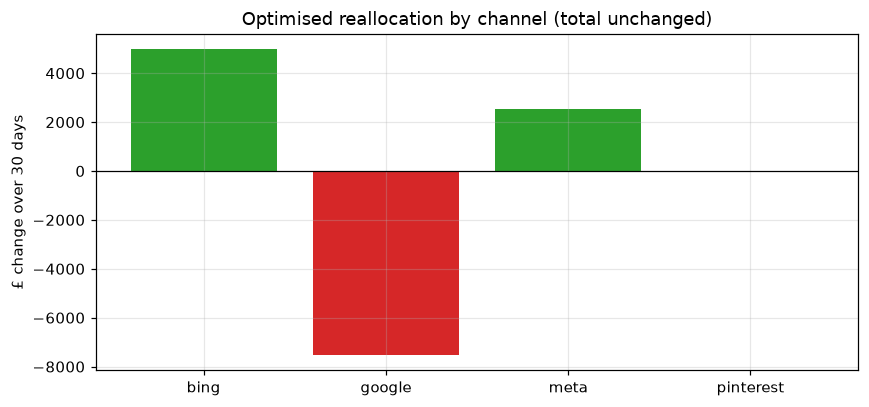

In [64]:
BOUNDS = {"bing": (1.0, 1.5), "google": (0.7, 1.0), "meta": (1.0, 1.3), "pinterest": (1.0, 1.0)}   # multipliers
bnds = [BOUNDS[c] for c in CHANNELS]

def total_budget_gap(m):                              # must equal 0: total budget is unchanged
    return float((base * m).sum() - base.sum())

def neg_mean_gain(m):                                 # minimise the negative = maximise customers
    return -delta_customers(P, base * m, base).mean()

start = np.array([1.0, 0.85, 1.1, 1.0])               # starting point inside the bounds
res = minimize(neg_mean_gain, start, method="SLSQP", bounds=bnds,
               constraints=[{"type": "eq", "fun": total_budget_gap}], options={"eps": 1e-3, "maxiter": 200})
m_opt = res.x
realloc_all = base * m_opt
assert abs(realloc_all.sum() - base.sum()) < 1.0, "total budget must stay unchanged"
moved_per_day = np.clip(base - realloc_all, 0, None).sum()
print("optimizer finished:", res.success, "|", res.message)
print(pd.DataFrame({"now £/day": base.round(0), "new £/day": realloc_all.round(0), "multiplier": m_opt.round(3),
                    "change £ over 30d": ((realloc_all - base) * HORIZON).round(0)}, index=CHANNELS))
print(f"Moved £{moved_per_day * HORIZON:,.0f} over 30 days = {moved_per_day / base.sum():.1%} of budget "
      f"(first version: 2.2%)")

# compare with the simple rule and the other plans on the full posterior
SCEN5 = {k: v for k, v in SCEN.items() if not k.startswith("5.")}
SCEN5[f"5. Optimised 4-channel reallocation (£{moved_per_day * HORIZON:,.0f} moved)"] = realloc_all
scen_table5, scen_draws5 = evaluate(P, SCEN5, BASE_KEY)
last = scen_table5.index[-1]                                    # строка плана 5
scen_table5.loc[last, ["Cost per extra customer £", "P(cost < £40)"]] = np.nan
scen_table5.loc[last, "P(more customers than baseline)"] = np.mean(scen_draws5[last] > 0)
display(scen_table5.round(2).T)
scen_table5.round(2).to_csv(f"{OUT_DIR}/scenario_table_v2.csv")

d5 = scen_draws5[list(SCEN5)[-1]]
print(f"Expected gain: +{d5.mean():,.0f} new customers over 30 days "
      f"(90% range {np.percentile(d5, 5):,.0f} to {np.percentile(d5, 95):,.0f}); "
      f"probability it beats the baseline: {np.mean(d5 > 0):.0%}")

# stability of the gain across the model variants from section 10b
rows = []
for name, Pv in variant_P.items():
    dv = delta_v(Pv, realloc_all, base)
    rows.append({"variant": name, "gain mean": round(dv.mean()), "5%": round(np.percentile(dv, 5)),
                 "95%": round(np.percentile(dv, 95)), "P(gain>0)": round(float(np.mean(dv > 0)), 2)})
display(pd.DataFrame(rows).set_index("variant"))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(CHANNELS, (realloc_all - base) * HORIZON, color=["tab:green" if v > 0 else "tab:red" for v in realloc_all - base])
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("£ change over 30 days"); ax.set_title("Optimised reallocation by channel (total unchanged)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/09_reallocation_optimised.png"); plt.show()

In [ ]:
def marginal_cpa_at(vec, ch, step=0.05):
    i = CHANNELS.index(ch)
    up = vec.copy(); up[i] *= 1 + step                       
    d = delta_customers(P, up, vec).mean()                   
    return vec[i] * step * HORIZON / d                       

for ch in CHANNELS:
    print(ch, "before:", round(marginal_cpa_at(base, ch), 1), "after:", round(marginal_cpa_at(realloc_all, ch), 1))

bing before: 15.4 after: 17.0
google before: 31.1 after: 29.0
meta before: 28.6 after: 28.6
pinterest before: 33.2 after: 33.2


In [ ]:
def run_opt(score_fn, bounds_dict):
    bnds = [bounds_dict[c] for c in CHANNELS]                     
    start = np.array([1.0, 0.9, 1.05, 1.0])                       
    res = minimize(lambda m: -score_fn(base * m), start, method="SLSQP", bounds=bnds,
                   constraints=[{"type": "eq", "fun": total_budget_gap}], options={"eps": 1e-3, "maxiter": 200})
    return res.x

def customers_by_channel(Pm, vec):                                 
    plan = np.tile(vec, (HORIZON, 1))
    return contributions_np(np.vstack([hist, plan]), Pm)[:, -HORIZON:, :].sum(axis=1)

# три способа оценить план
score_mean = lambda v: delta_customers(P, v, base).mean()                         
score_cautious = lambda v: (lambda d: d.mean() - d.std())(delta_customers(P, v, base))   
score_models = lambda v: np.mean([delta_v(Pv, v, base).mean() for Pv in variant_P.values()])  

BOUNDS_A = {"bing": (1.0, 1.5), "google": (0.7, 1.0), "meta": (1.0, 1.3), "pinterest": (1.0, 1.0)}  
options = {
    "A. Bing cap 1.5x, mean": (score_mean, BOUNDS_A),
    "B. Bing cap 1.5x, mean minus spread": (score_cautious, BOUNDS_A),
    "C. Bing cap 1.5x, average over 5 models": (score_models, BOUNDS_A),
}
rows = []
for name, (fn, bd) in options.items():
    m = run_opt(fn, bd); v = base * m
    d = delta_customers(P, v, base)
    by_ch = (customers_by_channel(P, v) - customers_by_channel(P, base)).mean(axis=0)
    rows.append({"option": name, "moved £ (30d)": round(np.clip(base - v, 0, None).sum() * HORIZON),
                 **{f"x {c}": round(mm, 2) for c, mm in zip(CHANNELS, m)},
                 "gain mean": round(d.mean()), "5%": round(np.percentile(d, 5)), "95%": round(np.percentile(d, 95)),
                 "P(gain>0)": round(float(np.mean(d > 0)), 2),
                 **{f"customers {c}": round(x) for c, x in zip(CHANNELS, by_ch)}})
display(pd.DataFrame(rows).set_index("option"))

,moved £ (30d),x bing,x google,x meta,x pinterest,gain mean,5%,95%,P(gain>0),customers bing,customers google,customers meta,customers pinterest
option,,,,,,,,,,,,,
"A. Bing cap 1.5x, mean",7505,1.5,0.89,1.03,1.0,145,-10,296,0.94,310,-254,89,0
"B. Bing cap 1.5x, mean minus spread",5054,1.5,0.93,1.00,1.0,144,-7,289,0.94,310,-169,3,0
"C. Bing cap 1.5x, average over 5 models",13395,1.5,0.80,1.11,1.0,139,-30,307,0.92,310,-465,294,0


- Reallocating the budget without additional spending is expected to bring in approximately 145 more clients per month—an increase of about 1% over the baseline of 12,558 clients—with a 94% probability that this approach will outperform the current one.
- After the move Google's next customer costs about the same as Meta's (£29.0 vs £28.6), so moving money to Meta would add almost nothing.
- Most of the extra growth comes from Bing because it attracts customers much cheaper than Google, meaning trimming Google frees up money while losing very few buyers.
- Option B appears to be the most effective plan, as it delivers the expected growth in the customer base while moving less cash and carrying less risk.
- These metrics vary depending on the model settings: the expected gain differs across various tests, and in some configurations, there is a slight risk of a decline—meaning that growth is likely, but not guaranteed.
- Bing has set a 1.5x limit on scaling, as going beyond this threshold would rely on unverified data—meaning any further increase would be purely a guess.


## 11. Recommendation and a small practical test

Recommendation
- Meta: add first. Largest volume lever. Test +20% before scaling further (see the test plan below).
- Bing: add. Cheapest channel (about £15 per extra customer at +10%), but small in volume.
- Google: reduce moderately, toward the floor of the bounds in section 10c. It is the most saturated channel; the cost of the next customer rises fastest there.
- Pinterest: hold. Highest cost and least certainty.
- Do not cut total spend to save money. Cutting loses more customers than it saves in money (section 9, plan 4).

Test: Meta +20% for 30 days

In [27]:
# --- test design: choose the test ----------------------------------------------------
test_channel = "meta"      # channel to test (the biggest volume lever)
test_pct = 0.20            # size of the increase: +20% for 30 days

cheapest = marg_cost.idxmin()
most_expensive = marg_cost.idxmax()

v = base_daily.to_numpy().copy()
v[CHANNELS.index(test_channel)] *= 1 + test_pct
d = delta_customers(P, v)
extra = base_daily[test_channel] * test_pct * HORIZON
lo, hi = np.percentile(d, [5, 95])

print(f"TEST: raise {test_channel} by {test_pct:.0%} for {HORIZON} days")
print(f"  budget: from £{base_daily[test_channel] * HORIZON:,.0f} to £{base_daily[test_channel] * HORIZON + extra:,.0f} over 30 days (extra £{extra:,.0f})")
print(f"  model expects {d.mean():,.0f} extra customers over 30 days (90% range {lo:,.0f} to {hi:,.0f}), about £{extra / d.mean():,.1f} per extra customer")
print(f"  per week: about {d.mean() * 7 / HORIZON:,.0f} extra customers (range {lo * 7 / HORIZON:,.0f} to {hi * 7 / HORIZON:,.0f})")
print("  decision rules, reviewed weekly:")
print(f"    INCREASE further if the measured cost per extra customer <= £{CPA_TARGET:.0f} and results are inside the predicted range")
print(f"    REDUCE / stop if the measured cost per extra customer > £{CPA_TARGET:.0f} for two weeks in a row")
print("    INVESTIGATE if results fall outside the 90% range (promotion, stock, tracking change, competitor, seasonality)")
print("  control: keep a few regions on the old budget so that season and promotions can be separated from the ads")
print(f"  for information: cheapest extra customers: {cheapest}; highest marginal cost: {most_expensive}")
display(channel_table := pd.DataFrame({"daily spend £": base_daily.round(0),
                                       "marginal cost £ (+10% step)": marg_cost.round(1)}))

TEST: raise meta by 20% for 30 days
  budget: from £75,282 to £90,338 over 30 days (extra £15,056)
  model expects 526 extra customers over 30 days (90% range 488 to 566), about £28.6 per extra customer
  per week: about 123 extra customers (range 114 to 132)
  decision rules, reviewed weekly:
    INCREASE further if the measured cost per extra customer <= £40 and results are inside the predicted range
    REDUCE / stop if the measured cost per extra customer > £40 for two weeks in a row
    INVESTIGATE if results fall outside the 90% range (promotion, stock, tracking change, competitor, seasonality)
  control: keep a few regions on the old budget so that season and promotions can be separated from the ads
  for information: cheapest extra customers: bing; highest marginal cost: pinterest


,daily spend £,marginal cost £ (+10% step)
bing,331.0,15.4
google,2265.0,31.6
meta,2509.0,28.6
pinterest,635.0,33.3


The test: Meta +20% for 30 days.
- Budget: about £75k to £90k over 30 days (+£15k).
- Model estimate, to be confirmed by the test and not a guarantee: about 526 extra new customers over 30 days (90% range 488-566), roughly £29 each against the £40 limit. That is about 120 a week.
- Weekly review: scale up if the measured cost per extra customer is £40 or less and results sit inside the predicted range; stop if it is above £40 two weeks in a row; investigate if results fall outside the range.
- Keep a control group (for example, a few regions stay on the old budget). Without one, the "measured" value relies on the model's own forecast.
- Why +20% and not +10%? +10% (about 263 customers over the month) is easy to lose in daily noise. +20% is big enough to see and still close to spend levels the model knows.

## 12. Limits, and how AI was used

**Trust more**
- All four channels are under £40 per extra customer at today's spend; Bing is the cheapest and Google gets expensive first.
- The maths is checked: my NumPy version matches the library (0.0000% gap), a manual loop matches it, and baseline vs itself gives 0.
- Section 10b testing shows that the core recommendations—primarily to scale efforts on Meta and Bing, while exercising caution with Google—remain valid across all five model variants. At the same time, the specific rankings based on spending levels shift, and the recommendation to maintain a presence on Pinterest is the least robust, given the platform’s high sensitivity to seasonality.

**Needs more evidence**
- Meta not saturating. Saturation is hard to see when spend is far below its peak, and the high-spend days are Black Friday days with big discounts. A rough cross-check: the 2025 sale had about £158k more spend than 2024 (same discounts) and about 3,559 more customers, about £44 each. This is not a direct comparison, but it exceeds the £29 in the model, so costs during sales could rise faster.
- Pinterest (wide range), any investment above 20-40% of current spend, and promotion effects (only two Black Friday instances in the data).
- The ranges reflect uncertainty in the fitted parameters, not the chance that the model structure is wrong. The 98% coverage in section 4 shows the ranges are, if anything, too wide.
- The 30-day window ignores effects after day 30, so extra customers are slightly understated.
- The regression in section 4b uses the same calendar data as the MMM. It’s a good test of ad impact, but not a completely separate model.

**I would reject the results if**
- r_hat > 1.01 or there were divergences
- the NumPy check disagreed with the library
- the model lost to a plain weekday average, or the no-media regression matched it
- the conclusions flipped under the small changes in section 10b

**Prediction is not causation.** Spend rises with discounts and season, ad platforms show ads to people who would have bought anyway, and there are only 730 days. Only a controlled test, like the Meta +20% above, shows what ads really cause.

---

**How AI was used.** AI wrote the first version of the code and the draft text. I ran it, checked it and corrected it. What got caught:
- Units: the first version only printed the units. I added real checks (ranges, whole numbers, revenue-to-spend ratio, order value).
- Unusual days: it used made-up cut-offs (0.5x and 1.6x of the median). I replaced them with a rolling median/MAD rule, and added a spend column because it only looked at customers.
- Model target: the library needs the target to be called y; the first version crashed.
- Variable name: the library calls it 'channel_contribution', not 'channel_contributions'; the engine check failed until fixed.
- Meta's flat curve: it was initially noted that this is “logical (the law of diminishing returns),” even though costs increased by only 0.6%. Now, the exact figure for this increase is provided, and I have offered an explanation for it (the initial segment of the curve is linear; in Google’s case, using the same code, the curve bends).
- Averaged parameters: in the example provided, 664 clients were identified based on averaged parameters, with the discrepancy characterized as insignificant. When all samples are taken into account, however, the result is 526; thus, the manual check relies on one specific sample, whereas the figure in the heading incorporates all of them.
- Test channel: the draft picked the cheapest channel (Bing) instead of the one I meant (Meta). The channel is now set explicitly.
- Over-confident wording in my first notes ("configured just right", "guaranteed", "mathematical proof", Google "can absorb bigger budgets" when its high lambda means it saturates fastest) was rewritten after checking against the numbers.